<h2>IS453 Financial Analytics</h2><h2>Group Assignment - Home Improvement Loan Scorecard</h2>

### Step 3: Exploratory Data Analysis (EDA)

This notebook follows `02_merged_data.ipynb`. It explores `merged_data.csv`, the merged application and flattened bureau data for the Home Improvement Loan segment

1. Data examination
2. Univariate analysis (missing values, numerical and categorical characteristics)
3. Bivariate analysis against `TARGET` (KDE plots, countplots, normalised stacked bar charts)
4. Correlation matrix and heatmaps

This dataset has **159 columns**, so every characteristic is profiled through automated summary tables and detailed charts are drawn only for important or unusual characteristics.

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# show complete summary tables and format floats for readability
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.float_format', '{:,.4f}'.format)

# keep figures readable but light
plt.rcParams['figure.dpi'] = 80
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

## 3.1 Data Examination

### 3.1.1 Load and understand the dataset

We start by loading the data and checking its size, structure and target distribution. The counts are recalculated from the file and compared with the reference values from the earlier verification of `merged_data.csv`.

In [18]:
# load the merged dataset (stop with a clear error if it is missing)
merged_path = 'data/merged_data.csv'
if not os.path.exists(merged_path):
    raise FileNotFoundError(f'{merged_path} not found. Run 02_merged_data.ipynb first.')

df = pd.read_csv(merged_path)

# fingerprint of the original data, used at the end to prove it was not modified
original_fingerprint = pd.util.hash_pandas_object(df, index=True).sum()

print(f'Rows: {df.shape[0]:,}')
print(f'Columns: {df.shape[1]}')

Rows: 213,312
Columns: 158


In [19]:
# first five records (all columns)
with pd.option_context('display.max_columns', None):
    display(df.head())

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,BUREAU_LOAN_COUNT,ACTIVE_LOAN_COUNT,ADVERSE_STATUS_COUNT,ACTIVE_LOAN_RATIO,CREDIT_TYPE_DIVERSITY,TOTAL_ACTIVE_DEBT,DEBT_TO_CREDIT_RATIO,TOTAL_REVOLVING_LIMIT,MAX_DAYS_OVERDUE,OVERDUE_LOAN_COUNT,TOTAL_OVERDUE_AMOUNT,MAX_HIST_OVERDUE,TOTAL_PROLONGATIONS,OLDEST_CREDIT_AGE,MOST_RECENT_CREDIT_AGE,MAX_REMAINING_DURATION,LAST_CREDIT_END_AGE,LATEST_BUREAU_UPDATE_AGE,ACTIVE_CONSUMER_CREDIT_COUNT,ACTIVE_CREDIT_CARD_COUNT,MORTGAGE_COUNT,CAR_LOAN_COUNT,MICROLOAN_COUNT,_merge,AGE_YEARS,FLAG_DAYS_EMPLOYED_SPECIAL,EMPLOYMENT_YEARS,LOAN_TO_INCOME,ANNUITY_TO_INCOME,CREDIT_TO_GOODS_RATIO,INCOME_PER_FAMILY_MEMBER,HAS_BUREAU_HISTORY,BUREAU_DEBT_TO_INCOME,TOTAL_EXPOSURE_TO_INCOME,AVG_DEBT_PER_ACTIVE_LOAN,CREDIT_HISTORY_AGE_RATIO,ACTIVE_LOANS_PER_INCOME,EXISTING_DEBT_SHARE_OF_EXPOSURE
0,100002,1,Cash loans,M,N,Y,0,"202,500.0000","406,597.5000","24,700.5000","351,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0188,-9461,-637,"-3,648.0000",-2120,NaN,1,1,0,1,1,0,Laborers,1.0000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.0830,0.0247,0.0369,0.9722,0.6192,0.0143,0.0000,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.0220,0.0198,0.0000,0.0000,0.0250,0.0369,0.9722,0.6243,0.0144,0.0000,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.0000,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0000,2.0000,2.0000,2.0000,"-1,134.0000",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,8.0000,2.0000,0.0000,0.2500,2.0000,"245,781.0000",0.5099,"31,988.5650",0.0000,0.0000,0.0000,"5,043.6450",0.0000,3.9343,0.2820,2.1355,0.0986,0.0192,1.0000,1.0000,0.0000,0.0000,0.0000,both,25.9028,0,1.7440,2.0079,0.1220,1.1584,"202,500.0000",1,1.2137,3.2216,"122,890.5

`df.info()` with all 159 columns prints one line per column. A compact version is shown here; the full per-column data type and non-missing counts appear in the characteristic inventory (3.1.2) and the missing-value table (3.2.1).

In [20]:
# review data counts and types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 213312 entries, 0 to 213311
Columns: 158 entries, SK_ID_CURR to EXISTING_DEBT_SHARE_OF_EXPOSURE
dtypes: float64(98), int64(43), str(17)
memory usage: 285.1 MB


In [21]:
# numeric versus categorical columns, uniqueness, duplicates and missing values
numeric_cols = df.select_dtypes(include='number').columns.tolist()
categorical_cols = df.select_dtypes(exclude='number').columns.tolist()

n_goods = (df['TARGET'] == 0).sum()
n_bads = (df['TARGET'] == 1).sum()

overview = pd.DataFrame({'Result': [
    f'{len(df):,}',
    df.shape[1],
    len(numeric_cols),
    len(categorical_cols),
    f"{df['SK_ID_CURR'].nunique():,}",
    df.duplicated().sum(),
    df['SK_ID_CURR'].duplicated().sum(),
    f'{df.isnull().sum().sum():,}',
    (df.isnull().sum() > 0).sum(),
]}, index=['Rows', 'Columns', 'Numeric columns', 'Categorical columns', 'Unique applicants (SK_ID_CURR)',
           'Duplicated rows', 'Duplicated applicant IDs', 'Missing cells', 'Columns with missing values'])
overview

,Result
Rows,"213,312"
Columns,158
Numeric columns,141
Categorical columns,17
Unique applicants (SK_ID_CURR),"213,312"
Duplicated rows,0
Duplicated applicant IDs,0
Missing cells,"7,449,611"
Columns with missing values,98


In [22]:
# TARGET distribution
target_dist = pd.DataFrame({'Count': df['TARGET'].value_counts().sort_index(),
                            'Percent': df['TARGET'].value_counts(normalize=True).sort_index() * 100})
target_dist.index = ['Good (TARGET = 0)', 'Bad (TARGET = 1)']
target_dist

,Count,Percent
Good (TARGET = 0),196329,92.0384
Bad (TARGET = 1),16983,7.9616


In [23]:
# compare with the reference values from the earlier verification
reference_check = pd.DataFrame({
    'Reference': [213312, 159, 196329, 16983, 7.96],
    'Calculated': [len(df), df.shape[1], n_goods, n_bads, round(n_bads / len(df) * 100, 2)],
}, index=['Applicants', 'Columns', 'Goods (TARGET = 0)', 'Bads (TARGET = 1)', 'Bad rate %'])
reference_check['Match'] = reference_check['Reference'] == reference_check['Calculated']
display(reference_check)

if reference_check['Match'].all():
    print('No discrepancies against the reference values.')
else:
    print('DISCREPANCY:', reference_check.index[~reference_check['Match']].tolist())

,Reference,Calculated,Match
Applicants,"213,312.0000","213,312.0000",True
Columns,159.0000,158.0000,False
Goods (TARGET = 0),"196,329.0000","196,329.0000",True
Bads (TARGET = 1),"16,983.0000","16,983.0000",True
Bad rate %,7.9600,7.9600,True


DISCREPANCY: ['Columns']


**Interpretation**

- The file loads with 213,312 rows and 159 columns. Every reference value is reproduced exactly: 196,329 goods, 16,983 bads and a 7.96% bad rate.
- Each row is one applicant: `SK_ID_CURR` is unique and there are no duplicated rows.
- 143 columns are stored as numbers and 16 as text. Being stored as a number does not make a column a measurement; 3.1.2 classifies them properly.
- 100 of the 159 columns have at least one missing value (about 7.5 million missing cells in total), so missing data is a central theme of this EDA.

### 3.1.2 Classify characteristics
**Variable type** rules, applied in order:

| Type | Rule |
|---|---|
| Identifier | `SK_ID_CURR` |
| Binary flag | Only the values 0/1 (numeric) or exactly two text values |
| Date-relative | Measured relative to the application date: `DAYS_*` columns and the year-based ages/durations derived from them |
| Categorical | Text values |
| Discrete numeric | Whole numbers only and at most 50 distinct values (counts, ratings, hours) |
| Continuous numeric | All other numeric columns |

**Business category** is assigned from the column name and data dictionary meaning. The dictionary description is shown for application columns.

In [24]:
# column groups created in earlier steps (names only)
id_target_cols = ['SK_ID_CURR', 'TARGET']
bureau_cols = ['BUREAU_LOAN_COUNT', 'ACTIVE_LOAN_COUNT', 'ADVERSE_STATUS_COUNT', 'ACTIVE_LOAN_RATIO', 'CREDIT_TYPE_DIVERSITY',
               'TOTAL_ACTIVE_DEBT', 'DEBT_TO_CREDIT_RATIO', 'TOTAL_REVOLVING_LIMIT', 'MAX_DAYS_OVERDUE', 'OVERDUE_LOAN_COUNT',
               'TOTAL_OVERDUE_AMOUNT', 'MAX_HIST_OVERDUE', 'TOTAL_PROLONGATIONS', 'OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE',
               'MAX_REMAINING_DURATION', 'LAST_CREDIT_END_AGE', 'LATEST_BUREAU_UPDATE_AGE', 'ACTIVE_CONSUMER_CREDIT_COUNT',
               'ACTIVE_CREDIT_CARD_COUNT', 'MORTGAGE_COUNT', 'CAR_LOAN_COUNT', 'MICROLOAN_COUNT']
new_app_features = ['AGE_YEARS', 'FLAG_DAYS_EMPLOYED_SPECIAL', 'EMPLOYMENT_YEARS', 'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME',
                    'CREDIT_TO_GOODS_RATIO', 'INCOME_PER_FAMILY_MEMBER']
new_cross_features = ['HAS_BUREAU_HISTORY', 'BUREAU_DEBT_TO_INCOME', 'TOTAL_EXPOSURE_TO_INCOME', 'AVG_DEBT_PER_ACTIVE_LOAN',
                      'CREDIT_HISTORY_AGE_RATIO', 'ACTIVE_LOANS_PER_INCOME', 'EXISTING_DEBT_SHARE_OF_EXPOSURE']

expected = id_target_cols + bureau_cols + new_app_features + new_cross_features
not_found = [c for c in expected if c not in df.columns]
if not_found:
    raise KeyError(f'Expected columns not found in merged_data.csv: {not_found}')
print('All expected column groups found.')

# ages and durations measured relative to the application date
date_relative_cols = [c for c in df.columns if c.startswith('DAYS_')] + [
    'AGE_YEARS', 'EMPLOYMENT_YEARS', 'OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE',
    'MAX_REMAINING_DURATION', 'LAST_CREDIT_END_AGE', 'LATEST_BUREAU_UPDATE_AGE']

# building / property fields from the application data
building_suffixes = ('_AVG', '_MODE', '_MEDI')
building_cols = [c for c in df.columns if c.endswith(building_suffixes)]

All expected column groups found.


In [25]:
def get_source(col):
    if col in id_target_cols:
        return 'Identifier or target'
    if col in bureau_cols:
        return 'Flattened Bureau Data'
    if col in new_app_features:
        return 'Engineered application feature'
    if col in new_cross_features:
        return 'Engineered cross-dataset feature'
    return 'Original Application Data'


def get_variable_type(col):
    s = df[col]
    if col == 'SK_ID_CURR':
        return 'Identifier'
    n_unique = s.nunique()
    if not pd.api.types.is_numeric_dtype(s):
        return 'Binary flag' if n_unique == 2 else 'Categorical'
    values = s.dropna()
    if n_unique <= 2 and values.isin([0, 1]).all():
        return 'Binary flag'
    if col in date_relative_cols:
        return 'Date-relative'
    if (values % 1 == 0).all() and n_unique <= 50:
        return 'Discrete numeric'
    return 'Continuous numeric'


income_cols = ['AMT_INCOME_TOTAL', 'AMT_ANNUITY', 'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'INCOME_PER_FAMILY_MEMBER',
               'BUREAU_DEBT_TO_INCOME', 'TOTAL_EXPOSURE_TO_INCOME', 'ACTIVE_LOANS_PER_INCOME']
loan_cols = ['NAME_CONTRACT_TYPE', 'AMT_CREDIT', 'AMT_GOODS_PRICE', 'CREDIT_TO_GOODS_RATIO', 'NAME_TYPE_SUITE']
demographic_cols = ['CODE_GENDER', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
                    'NAME_FAMILY_STATUS', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
                    'AGE_YEARS', 'EMPLOYMENT_YEARS', 'FLAG_DAYS_EMPLOYED_SPECIAL']
housing_cols = ['FLAG_OWN_REALTY', 'NAME_HOUSING_TYPE', 'FLAG_OWN_CAR', 'OWN_CAR_AGE'] + building_cols
delinquency_cols = ['ADVERSE_STATUS_COUNT', 'MAX_DAYS_OVERDUE', 'OVERDUE_LOAN_COUNT', 'TOTAL_OVERDUE_AMOUNT',
                    'MAX_HIST_OVERDUE', 'TOTAL_PROLONGATIONS']
history_cols = ['OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE', 'MAX_REMAINING_DURATION', 'LAST_CREDIT_END_AGE',
                'LATEST_BUREAU_UPDATE_AGE', 'CREDIT_HISTORY_AGE_RATIO']


def get_business_category(col):
    if col in income_cols:
        return 'Income and affordability'
    if col in loan_cols:
        return 'Loan characteristics'
    if col in demographic_cols:
        return 'Employment and demographics'
    if col in housing_cols:
        return 'Housing and property'
    if col in delinquency_cols:
        return 'Delinquency'
    if col in history_cols or col.startswith('AMT_REQ_CREDIT_BUREAU'):
        return 'Credit history and recency'
    if col in bureau_cols or col in new_cross_features:
        return 'Historical credit exposure'
    if col.startswith('FLAG_') or col in ['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']:
        return 'Contact and document flags'
    if col.startswith(('REGION_', 'REG_', 'LIVE_')) or 'SOCIAL_CIRCLE' in col:
        return 'Region and social circle'
    return 'Other'


# data dictionary descriptions (application data only)
data_dict = pd.read_excel('data/raw/IS453 Group Assignment - Data Dict.xlsx', sheet_name='Application Data')
app_descriptions = data_dict.set_index('Row')['Description']

inventory = pd.DataFrame({
    'Source': [get_source(c) for c in df.columns],
    'Data type': df.dtypes.astype(str).values,
    'Variable classification': [get_variable_type(c) for c in df.columns],
    'Business category': [get_business_category(c) for c in df.columns],
    'Unique values': df.nunique().values,
}, index=pd.Index(df.columns, name='Characteristic'))
inventory['Dictionary description'] = [app_descriptions.get(c, '') if get_source(c) == 'Original Application Data' or c in id_target_cols
                                       else 'See 01 / 03 notebook feature dictionary' for c in df.columns]
inventory.loc['TARGET', 'Variable classification'] = 'Binary flag (target)'
inventory

,Source,Data type,Variable classification,Business category,Unique values,Dictionary description
Characteristic,,,,,,
SK_ID_CURR,Identifier or target,int64,Identifier,Other,213312,ID of loan in our sample
TARGET,Identifier or target,int64,Binary flag (target),Other,2,Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of t...
NAME_CONTRACT_TYPE,Original Application Data,str,Binary flag,Loan characteristics,2,Identification if loan is cash or revolving
CODE_GENDER,Original Application Data,str,Categorical,Employment and demographics,3,Gender of the client
FLAG_OWN_CAR,Original Application Data,str,Binary flag,Housing and property,2,Flag if the client owns a car
FLAG_OWN_REALTY,Original Application Data,str,Categorical,Housing and property,1,Flag if client owns a house or flat
CNT_CHILDREN,Original Application Data,int64,Discrete numeric,Employment and demographics,13,Number of children the client has
AMT_INCOME_TOTAL,Original Application Data,float64,Continuous numeric,Income and affordability,1635,Income of the client
AMT_CREDIT,Original Application Data,float64,Continuous numeric,Loan characteristics,5074,Credit amount of the loan


In [26]:
# counts by source and variable type
pd.crosstab(inventory['Source'], inventory['Variable classification'], margins=True, margins_name='Total')

Variable classification,Binary flag,Binary flag (target),Categorical,Continuous numeric,Date-relative,Discrete numeric,Identifier,Total
Source,,,,,,,,
Engineered application feature,1,0,0,4,2,0,0,7
Engineered cross-dataset feature,1,0,0,6,0,0,0,7
Flattened Bureau Data,0,0,0,8,5,10,0,23
Identifier or target,0,1,0,0,0,0,1,2
Original Application Data,36,0,13,50,5,15,0,119
Total,38,1,13,68,12,25,1,158


In [27]:
# counts by business category
inventory['Business category'].value_counts().to_frame('Characteristics')

,Characteristics
Business category,
Housing and property,51
Contact and document flags,29
Historical credit exposure,15
Employment and demographics,13
Region and social circle,13
Credit history and recency,12
Income and affordability,8
Other,6
Delinquency,6


In [28]:
# helper lists used throughout the notebook
var_type = inventory['Variable classification']
binary_cols = var_type.index[var_type == 'Binary flag'].tolist()
continuous_cols = var_type.index[var_type == 'Continuous numeric'].tolist()
discrete_cols = var_type.index[var_type == 'Discrete numeric'].tolist()
date_cols = var_type.index[var_type == 'Date-relative'].tolist()
text_cols = var_type.index[var_type == 'Categorical'].tolist()
numeric_profile_cols = continuous_cols + discrete_cols + date_cols

print('FLAG_DOCUMENT_2 values:')
print(df['FLAG_DOCUMENT_2'].value_counts().to_string())
print(f"\nNumeric columns that are binary 0/1 flags: {sum(pd.api.types.is_numeric_dtype(df[c]) for c in binary_cols)}")

FLAG_DOCUMENT_2 values:
FLAG_DOCUMENT_2
0    213300
1        12

Numeric columns that are binary 0/1 flags: 34


**Interpretation**

- Of the 159 columns, 70 are continuous, 25 discrete, 12 date-relative, 13 categorical and 37 binary flags, plus the identifier and the target.
- **Housing and property** is the largest business category (51 columns), almost entirely the 47 building `_AVG` / `_MODE` / `_MEDI` fields. **Contact and document flags** is next (29). The categories most directly linked to credit risk are much smaller: income and affordability (8), loan characteristics (6), delinquency (6), historical credit exposure (15) and credit history (12). The column count is therefore not a guide to where the predictive information sits.
- `FLAG_DOCUMENT_2` is 1 for only 12 of 213,312 applicants. This shows why flags must be profiled as categories: the useful questions are how many applicants have the flag and how their bad rate compares, not its mean or skewness.

## 3.2 Univariate Analysis

Univariate analysis examines one characteristic at a time. This section covers missing values; Sections 3 and 4 cover the numerical and categorical distributions.

### 3.2.1 Missing-value analysis

In [29]:
# missing values for every column
missing_table = pd.DataFrame({
    'Missing count': df.isnull().sum(),
    'Missing %': df.isnull().mean() * 100,
    'Non-missing count': df.notnull().sum(),
    'Source': inventory['Source'],
    'Variable type': inventory['Variable classification'],
}).sort_values('Missing %', ascending=False)
missing_table.index.name = 'Characteristic'
missing_table

,Missing count,Missing %,Non-missing count,Source,Variable type
Characteristic,,,,,
COMMONAREA_AVG,147990,69.3773,65322,Original Application Data,Continuous numeric
COMMONAREA_MODE,147990,69.3773,65322,Original Application Data,Continuous numeric
COMMONAREA_MEDI,147990,69.3773,65322,Original Application Data,Continuous numeric
NONLIVINGAPARTMENTS_AVG,147172,68.9938,66140,Original Application Data,Continuous numeric
NONLIVINGAPARTMENTS_MEDI,147172,68.9938,66140,Original Application Data,Continuous numeric
NONLIVINGAPARTMENTS_MODE,147172,68.9938,66140,Original Application Data,Continuous numeric
FONDKAPREMONT_MODE,144859,67.9094,68453,Original Application Data,Categorical
LIVINGAPARTMENTS_AVG,144850,67.9052,68462,Original Application Data,Continuous numeric
LIVINGAPARTMENTS_MODE,144850,67.9052,68462,Original Application Data,Continuous numeric


In [30]:
# missingness distribution across characteristics
missing_band = pd.cut(missing_table['Missing %'], bins=[-0.001, 0, 5, 20, 40, 60, 100],
                      labels=['0%', 'Greater than 0% to 5%', 'Greater than 5% to 20%', 'Greater than 20% to 40%',
                              'Greater than 40% to 60%', 'Greater than 60%'])
missing_band.value_counts().sort_index().to_frame('Number of characteristics')

,Number of characteristics
Missing %,
0%,60
Greater than 0% to 5%,12
Greater than 5% to 20%,30
Greater than 20% to 40%,6
Greater than 40% to 60%,33
Greater than 60%,17


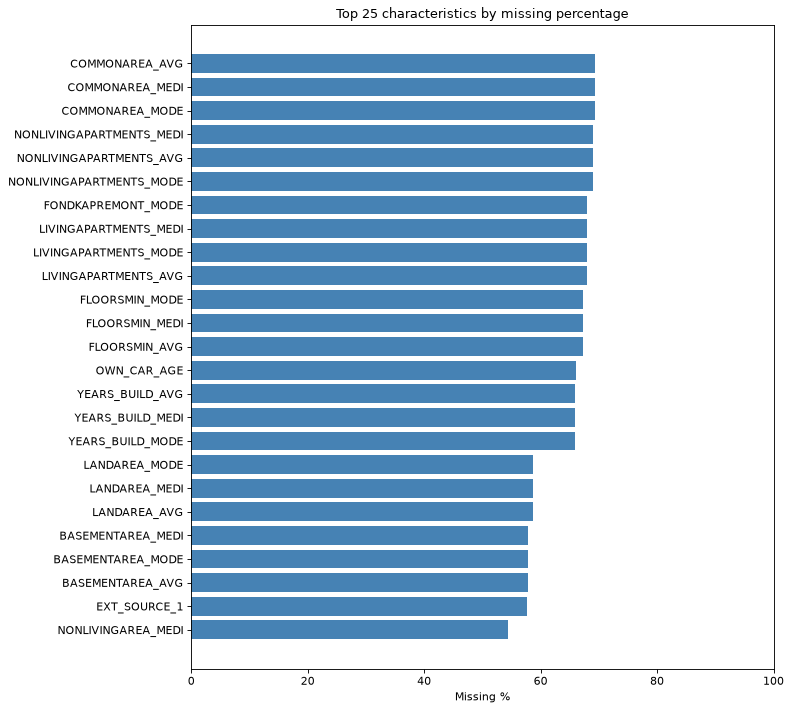

In [31]:
# 25 columns with the highest missing percentage
top_missing = missing_table.head(25).sort_values('Missing %')

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top_missing.index, top_missing['Missing %'], color='steelblue')
ax.set_xlabel('Missing %')
ax.set_title('Top 25 characteristics by missing percentage')
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

**Interpretation**

- 60 characteristics are complete, and 12 more are missing for less than 5% of applicants.
- **50 characteristics are more than 40% missing**, 17 of them more than 60%. Apart from `OWN_CAR_AGE` (66.1%, presumably applicants without a car) and `EXT_SOURCE_1` (57.7%), they are all building / property fields (46.7% to 69.4%).
- The bar chart shows the building variables missing in blocks of three: the `_AVG`, `_MODE` and `_MEDI` versions of a measure always have exactly the same missing count, because they come from the same source record.
- The 30 characteristics in the 5-20% band are mainly bureau characteristics, which are missing at exactly 14.75%, the share of applicants without bureau history.

#### Missingness by applicant

,Applicants,% of applicants
0,3165,1.4837
1-3,28536,13.3776
4-10,25156,11.7931
11-20,16274,7.6292
21-40,29882,14.0086
41-60,92674,43.4453
61-80,2470,1.1579
More than 80,15155,7.1046


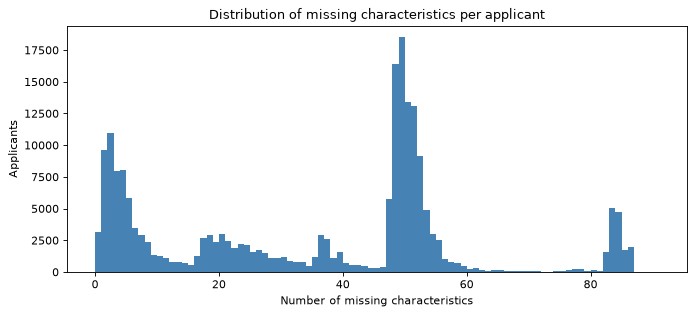

In [61]:
# number of missing characteristics per applicant
missing_per_applicant = df.isnull().sum(axis=1)

applicant_missing = pd.DataFrame({'Result': [
    f'{(missing_per_applicant == 0).sum():,}',
    f'{(missing_per_applicant > 0).sum():,}',
    f'{(missing_per_applicant > 3).sum():,}',
    f'{(missing_per_applicant > 3).mean() * 100:.2f}%',
    f'{missing_per_applicant.mean():.2f}',
    f'{missing_per_applicant.median():.0f}',
    f'{missing_per_applicant.max()}',
]}, index=['Applicants with no missing characteristics', 'Applicants with at least one missing characteristic',
           'Applicants with more than three missing characteristics', '% of applicants with more than three missing',
           'Mean missing characteristics per applicant', 'Median missing characteristics per applicant',
           'Maximum missing characteristics for one applicant'])
applicant_missing


# distribution of missing counts per applicant
missing_count_band = pd.cut(missing_per_applicant, bins=[-1, 0, 3, 10, 20, 40, 60, 80, df.shape[1]],
                            labels=['0', '1-3', '4-10', '11-20', '21-40', '41-60', '61-80', 'More than 80'])
band_table = missing_count_band.value_counts().sort_index().to_frame('Applicants')
band_table['% of applicants'] = band_table['Applicants'] / len(df) * 100
display(band_table)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(missing_per_applicant, bins=range(0, missing_per_applicant.max() + 2), color='steelblue')
ax.set_xlabel('Number of missing characteristics')
ax.set_ylabel('Applicants')
ax.set_title('Distribution of missing characteristics per applicant')
plt.show()

**Interpretation**

- Only 3,165 applicants (1.5%) have no missing characteristic. 183,080 (85.8%) have more than three.
- The distribution is clustered rather than smooth. 43.4% of applicants are missing 41-60 characteristics, which matches the block of 47 building variables being absent together. The 7.2% missing more than 80 combine that block with missing bureau history.
- Missingness follows a few **structural patterns** (no building record, no bureau record, pensioner employment fields), not random gaps. That is useful, because each pattern can be handled as a group in data preparation.

#### Bureau-specific missingness

The merge in Step 2 was a LEFT JOIN, so applicants without any bureau record have **every** bureau characteristic missing. This is *structural* missingness: the information does not exist, and its absence is itself captured by `HAS_BUREAU_HISTORY`. It is different from a value that is missing *within* reported bureau data (for example, a bureau record exists but the amount field was never reported).

The two groups are therefore summarised separately for the bureau and cross-dataset characteristics.

In [63]:
# bureau coverage
has_bureau = df['HAS_BUREAU_HISTORY'] == 1
coverage = pd.DataFrame({
    'Reference': [181841, 31471, 85.25],
    'Calculated': [has_bureau.sum(), (~has_bureau).sum(), round(has_bureau.mean() * 100, 2)],
}, index=['With bureau history', 'Without bureau history', 'Bureau coverage %'])
coverage['Match'] = coverage['Reference'] == coverage['Calculated']
coverage

,Reference,Calculated,Match
With bureau history,"181,841.0000","181,841.0000",True
Without bureau history,"31,471.0000","31,471.0000",True
Bureau coverage %,85.2500,85.2500,True


In [64]:
# missing % for bureau and cross-dataset characteristics, by bureau availability
bureau_related = bureau_cols + [c for c in new_cross_features if c != 'HAS_BUREAU_HISTORY']
bureau_missing = pd.DataFrame({
    'Missing % (all)': df[bureau_related].isnull().mean() * 100,
    'Missing % (with bureau history)': df.loc[has_bureau, bureau_related].isnull().mean() * 100,
    'Missing % (without bureau history)': df.loc[~has_bureau, bureau_related].isnull().mean() * 100,
    'Source': inventory.loc[bureau_related, 'Source'],
})

def missing_type(row):
    if row['Missing % (with bureau history)'] == 0:
        return 'Structural only (bureau record absent)'
    return 'Structural + missing within reported bureau data'

bureau_missing['Missingness type'] = bureau_missing.apply(missing_type, axis=1)
bureau_missing.sort_values('Missing % (with bureau history)', ascending=False)

,Missing % (all),Missing % (with bureau history),Missing % (without bureau history),Source,Missingness type
MAX_HIST_OVERDUE,40.6245,30.3485,100.0000,Flattened Bureau Data,Structural + missing within reported bureau data
DEBT_TO_CREDIT_RATIO,34.2967,22.9255,100.0000,Flattened Bureau Data,Structural + missing within reported bureau data
AVG_DEBT_PER_ACTIVE_LOAN,33.3188,21.7784,100.0000,Engineered cross-dataset feature,Structural + missing within reported bureau data
MAX_REMAINING_DURATION,32.7459,21.1064,100.0000,Flattened Bureau Data,Structural + missing within reported bureau data
LAST_CREDIT_END_AGE,25.4852,12.5890,100.0000,Flattened Bureau Data,Structural + missing within reported bureau data
TOTAL_REVOLVING_LIMIT,21.7442,8.2006,100.0000,Flattened Bureau Data,Structural + missing within reported bureau data
TOTAL_EXPOSURE_TO_INCOME,18.1767,4.0156,100.0000,Engineered cross-dataset feature,Structural + missing within reported bureau data
EXISTING_DEBT_SHARE_OF_EXPOSURE,18.1767,4.0156,100.0000,Engineered cross-dataset feature,Structural + missing within reported bureau data
BUREAU_DEBT_TO_INCOME,18.1767,4.0156,100.0000,Engineered cross-dataset feature,Structural + missing within reported bureau data
TOTAL_ACTIVE_DEBT,18.1767,4.0156,100.0000,Flattened Bureau Data,Structural + missing within reported bureau data


In [65]:
# application characteristics: is missingness different between the two groups?
app_side = [c for c in df.columns if c not in bureau_related + id_target_cols + ['HAS_BUREAU_HISTORY']]
app_missing_split = pd.DataFrame({
    'Missing % (with bureau history)': df.loc[has_bureau, app_side].isnull().mean() * 100,
    'Missing % (without bureau history)': df.loc[~has_bureau, app_side].isnull().mean() * 100,
})
app_missing_split['Difference (pp)'] = app_missing_split['Missing % (without bureau history)'] - app_missing_split['Missing % (with bureau history)']
app_missing_split = app_missing_split[(app_missing_split.iloc[:, :2] > 0).any(axis=1)]
print(f'Application characteristics with any missing values: {len(app_missing_split)}')
app_missing_split.sort_values('Difference (pp)', key=abs, ascending=False).head(15)

Application characteristics with any missing values: 69


,Missing % (with bureau history),Missing % (without bureau history),Difference (pp)
AMT_REQ_CREDIT_BUREAU_MON,0.0000,94.4107,94.4107
AMT_REQ_CREDIT_BUREAU_DAY,0.0000,94.4107,94.4107
AMT_REQ_CREDIT_BUREAU_HOUR,0.0000,94.4107,94.4107
AMT_REQ_CREDIT_BUREAU_QRT,0.0000,94.4107,94.4107
AMT_REQ_CREDIT_BUREAU_YEAR,0.0000,94.4107,94.4107
AMT_REQ_CREDIT_BUREAU_WEEK,0.0000,94.4107,94.4107
EXT_SOURCE_1,56.9360,62.2668,5.3308
OWN_CAR_AGE,65.3164,70.4839,5.1675
TOTALAREA_MODE,47.0746,50.4941,3.4195
EMERGENCYSTATE_MODE,46.2173,49.6012,3.3839


**Interpretation**

- Bureau coverage matches the reference exactly: 181,841 applicants with history and 31,471 (14.75%) without.
- **Structural missingness.** 29 bureau and cross-dataset characteristics are 100% missing for applicants without bureau history. For 19 of them, missingness among applicants *with* history is 0% (or practically 0%), so their missing values carry no information beyond `HAS_BUREAU_HISTORY` itself.
- **Missing within reported bureau data.** Ten characteristics are also missing for applicants who have bureau history: `MAX_HIST_OVERDUE` (30.3%), `DEBT_TO_CREDIT_RATIO` (22.9%), `AVG_DEBT_PER_ACTIVE_LOAN` (21.8%), `MAX_REMAINING_DURATION` (21.1%), `LAST_CREDIT_END_AGE` (12.6%), `TOTAL_REVOLVING_LIMIT` (8.2%), and the four debt-based characteristics (4.0% each). These need a separate explanation (below).
- **Unexpected finding:** the six application-side `AMT_REQ_CREDIT_BUREAU_*` enquiry counts are 0% missing for applicants with bureau history but 94.4% missing for those without. Although they come from the application file, they behave like bureau information and are effectively also structurally missing.
- `EXT_SOURCE_1` and the building fields are only slightly more often missing without bureau history (by 3-5 percentage points), so their missingness is largely unrelated to bureau coverage.

#### Important characteristics to investigate

The characteristics below have notable missingness. For each one, the data is checked for an explanation that can be **evidenced** from other columns, rather than assumed.

In [66]:
# missingness of the highlighted characteristics
focus_missing = ['MAX_HIST_OVERDUE', 'DEBT_TO_CREDIT_RATIO', 'MAX_REMAINING_DURATION', 'TOTAL_ACTIVE_DEBT',
                 'EMPLOYMENT_YEARS', 'EXT_SOURCE_1']
focus_table = pd.DataFrame({
    'Missing % (all)': df[focus_missing].isnull().mean() * 100,
    'Missing % (with bureau history)': df.loc[has_bureau, focus_missing].isnull().mean() * 100,
    'Missing % (without bureau history)': df.loc[~has_bureau, focus_missing].isnull().mean() * 100,
})
building_missing = df[building_cols].isnull().mean() * 100
focus_table.loc[f'Building variables ({len(building_cols)}): lowest'] = [building_missing.min(),
    df.loc[has_bureau, building_cols].isnull().mean().min() * 100, df.loc[~has_bureau, building_cols].isnull().mean().min() * 100]
focus_table.loc[f'Building variables ({len(building_cols)}): highest'] = [building_missing.max(),
    df.loc[has_bureau, building_cols].isnull().mean().max() * 100, df.loc[~has_bureau, building_cols].isnull().mean().max() * 100]
focus_table

,Missing % (all),Missing % (with bureau history),Missing % (without bureau history)
MAX_HIST_OVERDUE,40.6245,30.3485,100.0000
DEBT_TO_CREDIT_RATIO,34.2967,22.9255,100.0000
MAX_REMAINING_DURATION,32.7459,21.1064,100.0000
TOTAL_ACTIVE_DEBT,18.1767,4.0156,100.0000
EMPLOYMENT_YEARS,19.7973,19.6298,20.7651
EXT_SOURCE_1,57.7225,56.9360,62.2668
Building variables (47): lowest,46.7165,46.2173,49.6012
Building variables (47): highest,69.3773,69.0504,71.2656


In [67]:
# evidence for the missing-value mechanisms (counts only, nothing is filled)
hb = df[has_bureau]
special_emp = df['DAYS_EMPLOYED'] == 365243

evidence = pd.DataFrame({'Count': [
    df['EMPLOYMENT_YEARS'].isnull().sum(),
    special_emp.sum(),
    (df['EMPLOYMENT_YEARS'].isnull() & special_emp).sum(),
    hb['DEBT_TO_CREDIT_RATIO'].isnull().sum(),
    (hb['DEBT_TO_CREDIT_RATIO'].isnull() & (hb['ACTIVE_LOAN_COUNT'] == 0)).sum(),
    hb['MAX_REMAINING_DURATION'].isnull().sum(),
    (hb['MAX_REMAINING_DURATION'].isnull() & (hb['ACTIVE_LOAN_COUNT'] == 0)).sum(),
    hb['TOTAL_ACTIVE_DEBT'].isnull().sum(),
    (hb['TOTAL_ACTIVE_DEBT'].isnull() & (hb['ACTIVE_LOAN_COUNT'] > 0)).sum(),
    hb['MAX_HIST_OVERDUE'].isnull().sum(),
    df[building_cols].isnull().all(axis=1).sum(),
    df[building_cols].notnull().all(axis=1).sum(),
]}, index=[
    'EMPLOYMENT_YEARS missing',
    'DAYS_EMPLOYED = 365243 (special code)',
    'EMPLOYMENT_YEARS missing AND special code',
    'DEBT_TO_CREDIT_RATIO missing (with bureau history)',
    '... of which: no active bureau loan',
    'MAX_REMAINING_DURATION missing (with bureau history)',
    '... of which: no active bureau loan',
    'TOTAL_ACTIVE_DEBT missing (with bureau history)',
    '... of which: has at least one active bureau loan',
    'MAX_HIST_OVERDUE missing (with bureau history)',
    'Applicants missing ALL building variables',
    'Applicants with ALL building variables present',
])
evidence['Count'] = evidence['Count'].map('{:,}'.format)
evidence

,Count
EMPLOYMENT_YEARS missing,"42,230"
DAYS_EMPLOYED = 365243 (special code),"42,230"
EMPLOYMENT_YEARS missing AND special code,"42,230"
DEBT_TO_CREDIT_RATIO missing (with bureau history),"41,688"
... of which: no active bureau loan,"32,300"
MAX_REMAINING_DURATION missing (with bureau history),"38,380"
... of which: no active bureau loan,"32,300"
TOTAL_ACTIVE_DEBT missing (with bureau history),"7,302"
... of which: has at least one active bureau loan,"7,302"
MAX_HIST_OVERDUE missing (with bureau history),"55,186"


**Interpretation: missing-value mechanisms supported by the data**

| Characteristic | Evidence | Mechanism |
|---|---|---|
| `EMPLOYMENT_YEARS` | All 42,230 missing values coincide with `DAYS_EMPLOYED = 365243` | Not applicable (special code, mostly pensioners), by design in Step 2 |
| `DEBT_TO_CREDIT_RATIO` | 32,300 of the 41,688 missing values (with history) belong to applicants with **no active bureau loan** | Mathematically undefined (zero denominator), not unreported. The remaining 9,388 have an active loan, but no usable credit amount in currency 1. |
| `MAX_REMAINING_DURATION` | 32,300 of the 38,380 missing values (with history) have no active bureau loan | Not applicable; the remaining 6,080 have an active loan with no valid end date |
| `TOTAL_ACTIVE_DEBT` | All 7,302 missing values (with history) have at least one active loan | Genuinely **unreported** debt; must not be treated as zero |
| `MAX_HIST_OVERDUE` | 55,186 applicants with history have no value | Field not reported in the bureau records |
| Building variables | 99,652 applicants are missing **all** 47 and 55,421 have **all** 47 | Block missingness: the building record either exists or not |
| `EXT_SOURCE_1` | 57.7% missing, similar with and without bureau history | Source and meaning not documented; mechanism cannot be established from the data |

The same symbol (missing) therefore means four different things: *no bureau history*, *not applicable*, *undefined ratio* and *not reported*. These should be kept apart in data preparation and not filled with a single rule.

## 3.3 Numerical Univariate Analysis

### 3.3.1 Automated numerical summary
`SK_ID_CURR`, `TARGET` and the 0/1 flags are excluded because their averages have no business meaning as measurements.

Screening flags (indicators for follow-up, not judgments):

| Flag | Rule |
|---|---|
| Strong positive skew | skewness > 2 |
| Strong negative skew | skewness < -2 |
| Extreme range | full range (max - min) is at least 3 times the range of the central 98% (P99 - P1) |
| Low variability | P1 = P99, i.e. at least 98% of non-missing values share one value range point |
| Mean-median gap | Median skewness 3 x (mean - median) / std is beyond +/-1 |

In [68]:
def numeric_profile(col):
    s = df[col].dropna()
    p1, q1, median, q3, p99 = s.quantile([0.01, 0.25, 0.5, 0.75, 0.99])
    mean, std = s.mean(), s.std()
    skew = s.skew()
    flags = []
    if skew > 2:
        flags.append('Strong positive skew')
    if skew < -2:
        flags.append('Strong negative skew')
    if p99 == p1:
        flags.append('Low variability')
    elif (s.max() - s.min()) >= 3 * (p99 - p1):
        flags.append('Extreme range')
    if std > 0 and abs(3 * (mean - median) / std) > 1:
        flags.append('Mean-median gap')
    return {'Count': len(s), 'Mean': mean, 'Median': median, 'Std': std, 'Min': s.min(), 'Q1': q1, 'Q3': q3,
            'P99': p99, 'Max': s.max(), 'Skewness': skew, 'Flags': ', '.join(flags)}


numeric_summary = pd.DataFrame({c: numeric_profile(c) for c in numeric_profile_cols}).T
numeric_summary.index.name = 'Characteristic'
for c in ['Count', 'Mean', 'Median', 'Std', 'Min', 'Q1', 'Q3', 'P99', 'Max', 'Skewness']:
    numeric_summary[c] = numeric_summary[c].astype(float)
numeric_summary.insert(0, 'Variable type', inventory.loc[numeric_summary.index, 'Variable classification'])

print(f'Numeric characteristics profiled: {len(numeric_summary)}')
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(numeric_summary)

Numeric characteristics profiled: 105


,Variable type,Count,Mean,Median,Std,Min,Q1,Q3,P99,Max,Skewness,Flags
Characteristic,,,,,,,,,,,,
AMT_INCOME_TOTAL,Continuous numeric,"213,312.00","169,260.28","148,500.00","275,641.29","25,650.00","112,500.00","202,500.00","472,500.00","117,000,000.00",359.00,"Strong positive skew, Extreme range"
AMT_CREDIT,Continuous numeric,"213,312.00","588,522.52","508,495.50","395,054.11","45,000.00","270,000.00","808,650.00","1,800,000.00","4,050,000.00",1.17,
AMT_ANNUITY,Continuous numeric,"213,309.00","27,058.25","24,903.00","14,553.48","1,615.50","16,375.50","34,659.00","70,132.50","225,000.00",1.54,Extreme range
AMT_GOODS_PRICE,Continuous numeric,"213,089.00","527,213.82","450,000.00","360,433.99","40,500.00","234,000.00","679,500.00","1,755,000.00","4,050,000.00",1.28,
REGION_POPULATION_RELATIVE,Continuous numeric,"213,312.00",0.02,0.02,0.01,0.00,0.01,0.03,0.07,0.07,1.48,
OWN_CAR_AGE,Continuous numeric,"72,358.00",12.07,9.00,12.17,0.00,5.00,15.00,64.00,91.00,2.75,Strong positive skew
EXT_SOURCE_1,Continuous numeric,"90,183.00",0.51,0.52,0.21,0.02,0.35,0.69,0.89,0.96,-0.12,
APARTMENTS_AVG,Continuous numeric,"106,628.00",0.12,0.09,0.11,0.00,0.06,0.15,0.55,1.00,2.67,Strong positive skew
BASEMENTAREA_AVG,Continuous numeric,"90,049.00",0.09,0.08,0.08,0.00,0.04,0.11,0.39,1.00,3.60,Strong positive skew


In [69]:
# how many characteristics carry each screening flag
flag_names = ['Strong positive skew', 'Strong negative skew', 'Extreme range', 'Low variability', 'Mean-median gap']
flag_counts = pd.DataFrame({
    'Characteristics': [numeric_summary['Flags'].str.contains(f).sum() for f in flag_names],
    'Examples (highest absolute skewness first)': [
        ', '.join(numeric_summary[numeric_summary['Flags'].str.contains(f)]['Skewness'].abs()
                  .sort_values(ascending=False).head(6).index) for f in flag_names],
}, index=flag_names)
flag_counts

,Characteristics,Examples (highest absolute skewness first)
Strong positive skew,63,"AMT_INCOME_TOTAL, DEBT_TO_CREDIT_RATIO, MAX_HIST_OVERDUE, INCOME_PER_FAMILY_MEMBER, AMT_REQ_CREDIT_BUREAU_QRT, TOTAL..."
Strong negative skew,3,"YEARS_BEGINEXPLUATATION_MEDI, YEARS_BEGINEXPLUATATION_AVG, YEARS_BEGINEXPLUATATION_MODE"
Extreme range,45,"AMT_INCOME_TOTAL, DEBT_TO_CREDIT_RATIO, MAX_HIST_OVERDUE, INCOME_PER_FAMILY_MEMBER, AMT_REQ_CREDIT_BUREAU_QRT, TOTAL..."
Low variability,2,"AMT_REQ_CREDIT_BUREAU_DAY, AMT_REQ_CREDIT_BUREAU_HOUR"
Mean-median gap,19,"OBS_30_CNT_SOCIAL_CIRCLE, OBS_60_CNT_SOCIAL_CIRCLE, NONLIVINGAREA_AVG, NONLIVINGAREA_MODE, NONLIVINGAREA_MEDI, LATES..."


In [70]:
# most skewed characteristics in each direction
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(numeric_summary.sort_values('Skewness', ascending=False)[['Variable type', 'Median', 'Mean', 'P99', 'Max', 'Skewness']].head(12))
    display(numeric_summary.sort_values('Skewness')[['Variable type', 'Median', 'Mean', 'Min', 'Max', 'Skewness']].head(5))

,Variable type,Median,Mean,P99,Max,Skewness
Characteristic,,,,,,
AMT_INCOME_TOTAL,Continuous numeric,"148,500.00","169,260.28","472,500.00","117,000,000.00",359.00
DEBT_TO_CREDIT_RATIO,Continuous numeric,0.61,0.56,1.06,382.51,319.61
MAX_HIST_OVERDUE,Continuous numeric,0.00,"8,711.92","73,766.74","115,987,185.00",313.44
INCOME_PER_FAMILY_MEMBER,Continuous numeric,"75,000.00","92,998.44","337,500.00","39,000,000.00",205.36
AMT_REQ_CREDIT_BUREAU_QRT,Discrete numeric,0.00,0.27,2.00,261.00,148.21
TOTAL_OVERDUE_AMOUNT,Continuous numeric,0.00,243.48,27.00,"3,756,681.00",139.22
MICROLOAN_COUNT,Discrete numeric,0.00,0.04,1.00,44.00,29.30
AMT_REQ_CREDIT_BUREAU_DAY,Discrete numeric,0.00,0.01,0.00,9.00,27.40
MAX_DAYS_OVERDUE,Continuous numeric,0.00,4.86,16.00,"2,792.00",22.76


,Variable type,Median,Mean,Min,Max,Skewness
Characteristic,,,,,,
YEARS_BEGINEXPLUATATION_MEDI,Continuous numeric,0.98,0.98,0.00,1.00,-15.45
YEARS_BEGINEXPLUATATION_AVG,Continuous numeric,0.98,0.98,0.00,1.00,-15.38
YEARS_BEGINEXPLUATATION_MODE,Continuous numeric,0.98,0.98,0.00,1.00,-14.57
YEARS_BUILD_MODE,Continuous numeric,0.76,0.76,0.00,1.00,-0.96
YEARS_BUILD_MEDI,Continuous numeric,0.76,0.76,0.00,1.00,-0.92


**Interpretation**

- 107 numeric characteristics were profiled. Skewness is the dominant feature: **63 have skewness above 2**, and 45 carry the extreme-range flag (a few observations stretch the range to at least 3 times the central 98%).
- The most extreme cases: `AMT_INCOME_TOTAL` has a median of 148,500 and P99 of 472,500 but a maximum of 117,000,000 (skewness 359). `DEBT_TO_CREDIT_RATIO` has P99 of 1.06 but a maximum of 382.5. `MAX_HIST_OVERDUE` has P99 of 73,767 but a maximum of about 116 million. A handful of values drive these statistics.
- Only the three `YEARS_BEGINEXPLUATATION` building fields are strongly negatively skewed (values clustered near 1 with a tail towards 0).
- Two enquiry counts (`AMT_REQ_CREDIT_BUREAU_DAY` and `_HOUR`) have low variability: at least 98% of applicants have the same value (0).
- `DAYS_EMPLOYED` has a **positive** mean (70,356) even though employment days should be negative. This is the 365243 special code distorting the average (3.3.4).
- Skewness here is a screening signal. A skewed characteristic is not wrong, but it rules out equal-width bins and makes averages misleading.

### 3.3.2 Histograms
For heavily skewed characteristics (skewness > 2) a second, **restricted-range** view shows only values up to the 99th percentile so the shape of the bulk of the data is visible. The restricted view is a temporary filter for plotting; the data is not changed.

In [71]:
def plot_hist_group(cols, title):
    cols = [c for c in cols if c in df.columns]
    skipped = [c for c in cols if df[c].nunique() < 2]
    cols = [c for c in cols if c not in skipped]
    if skipped:
        print('Skipped (fewer than two distinct values):', skipped)

    # full range
    axes = df[cols].hist(figsize=(14, 3.2 * int(np.ceil(len(cols) / 3))), bins=50, layout=(-1, 3), color='steelblue')
    plt.suptitle(f'{title}: full range', y=1.0)
    plt.tight_layout()
    plt.show()

    # restricted view for heavily skewed characteristics
    skewed = [c for c in cols if numeric_summary.loc[c, 'Skewness'] > 2]
    if not skewed:
        print('No characteristic in this group has skewness > 2, so no restricted view is needed.')
        return
    n_rows = int(np.ceil(len(skewed) / 3))
    fig, axes = plt.subplots(n_rows, 3, figsize=(14, 3.2 * n_rows))
    for ax, c in zip(np.ravel(axes), skewed):
        p99 = df[c].quantile(0.99)
        shown = df.loc[df[c] <= p99, c]
        ax.hist(shown, bins=50, color='darkorange')
        ax.set_title(f'{c}\nrestricted to <= P99 ({df[c].notnull().sum() - len(shown):,} values not shown)', fontsize=10)
    for ax in np.ravel(axes)[len(skewed):]:
        ax.axis('off')
    plt.suptitle(f'{title}: restricted-range diagnostic view (values <= 99th percentile)', y=1.0)
    plt.tight_layout()
    plt.show()

#### Group A - Financial variables

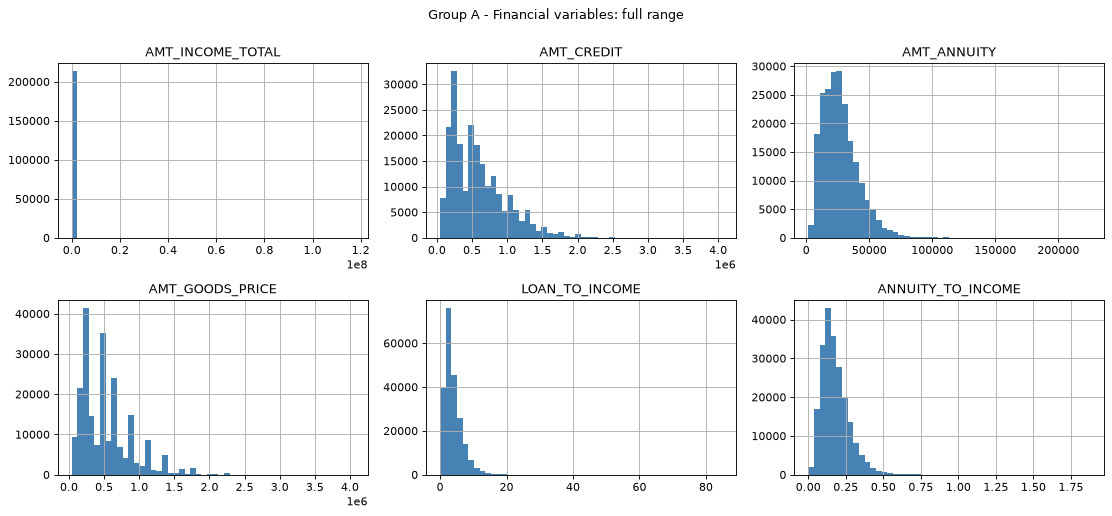

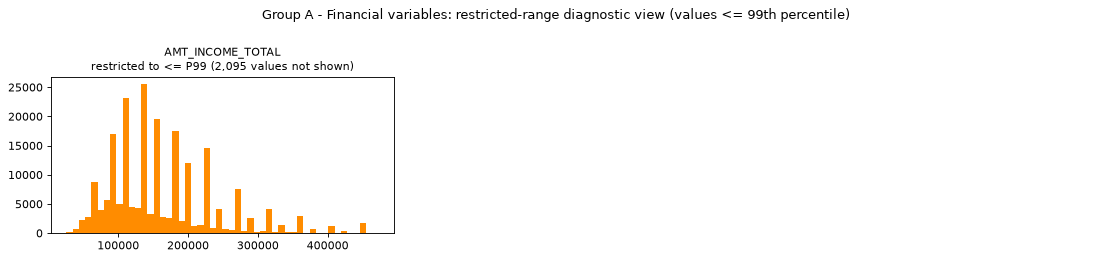

In [72]:
group_a = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME']
plot_hist_group(group_a, 'Group A - Financial variables')

**Interpretation**

- The full-range `AMT_INCOME_TOTAL` histogram is a single bar: one income of 117 million compresses everything else into the first bin. The restricted view (up to P99) shows the real shape, which is right-skewed with spikes at round income values.
- `AMT_CREDIT` and `AMT_GOODS_PRICE` are multi-modal, with peaks at round loan amounts, and right-skewed. Their shapes are almost identical, which anticipates their 0.99 correlation (3.6.2).
- `LOAN_TO_INCOME` and `ANNUITY_TO_INCOME` are right-skewed with long thin tails (up to about 85 and 1.9 respectively), but most applicants sit in a narrow band.

#### Group B - Bureau variables

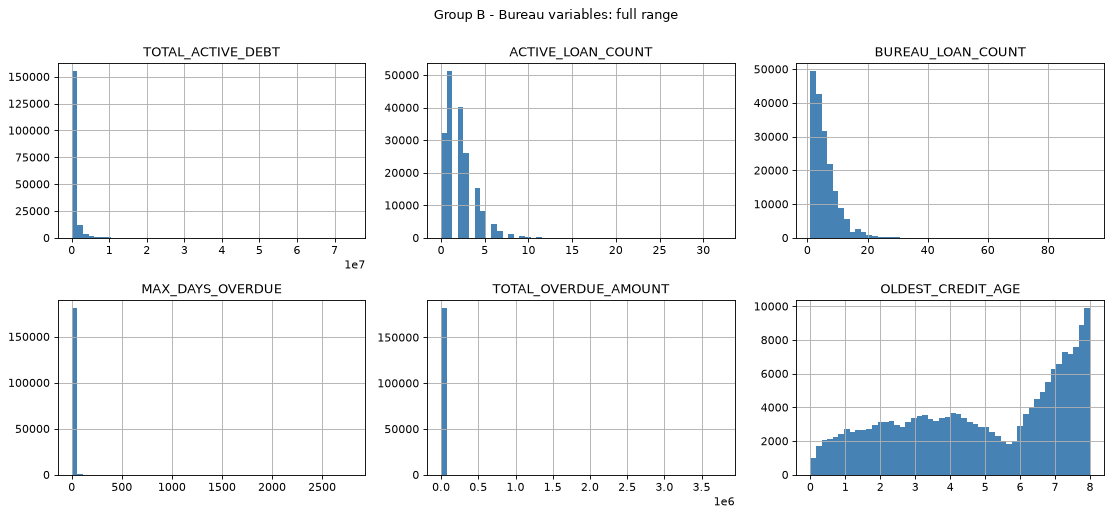

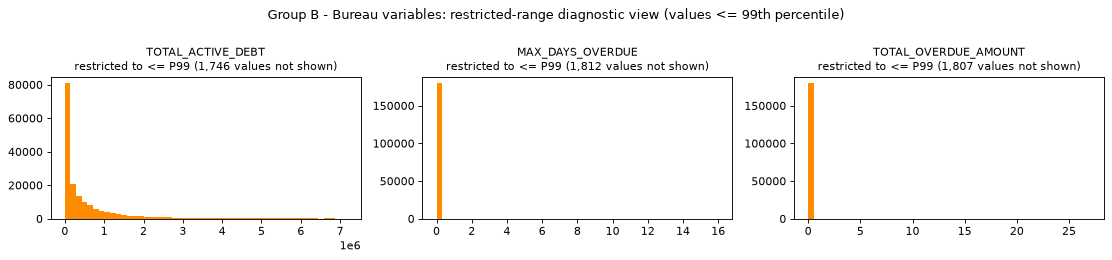

In [73]:
group_b = ['TOTAL_ACTIVE_DEBT', 'ACTIVE_LOAN_COUNT', 'BUREAU_LOAN_COUNT', 'MAX_DAYS_OVERDUE', 'TOTAL_OVERDUE_AMOUNT', 'OLDEST_CREDIT_AGE']
plot_hist_group(group_b, 'Group B - Bureau variables')

**Interpretation**

- `TOTAL_ACTIVE_DEBT` has a large spike at 0: at least a quarter of bureau applicants (Q1 = 0) have no active debt. A long right tail follows.
- `ACTIVE_LOAN_COUNT` and `BUREAU_LOAN_COUNT` are count distributions that fall off quickly.
- `MAX_DAYS_OVERDUE` and `TOTAL_OVERDUE_AMOUNT` are almost entirely 0 (98.7% of bureau applicants have no overdue loan). Their histograms are a single spike, so they are better analysed as "any overdue vs none" groups than as continuous measures.
- `OLDEST_CREDIT_AGE` piles up just below 8 years. This reflects the roughly 8-year window of the bureau data noted in Step 2, not real borrower behaviour.

#### Group C - Engineered variables

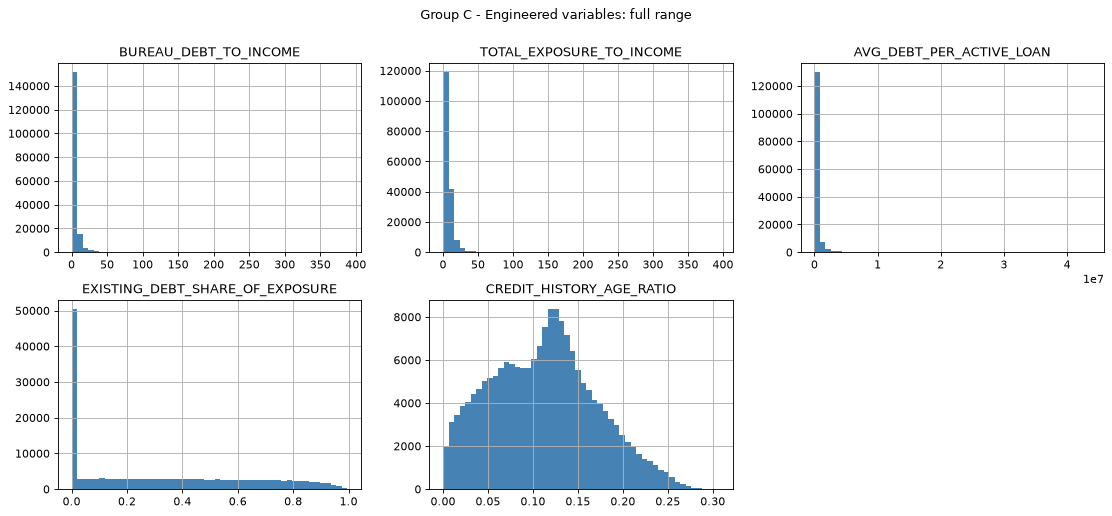

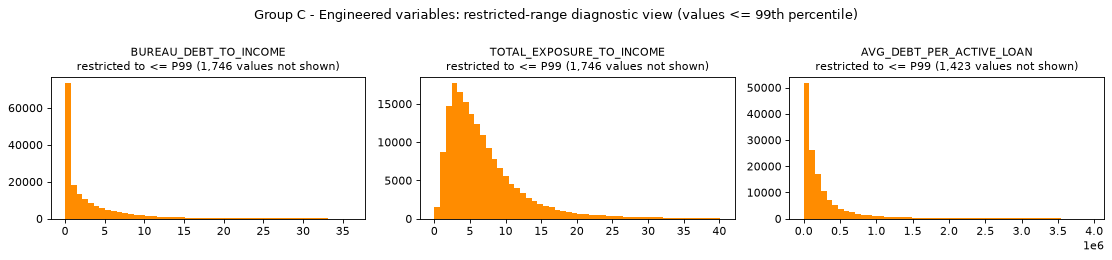

In [74]:
group_c = ['BUREAU_DEBT_TO_INCOME', 'TOTAL_EXPOSURE_TO_INCOME', 'AVG_DEBT_PER_ACTIVE_LOAN',
           'EXISTING_DEBT_SHARE_OF_EXPOSURE', 'CREDIT_HISTORY_AGE_RATIO']
plot_hist_group(group_c, 'Group C - Engineered variables')

**Interpretation**

- The debt-based ratios (`BUREAU_DEBT_TO_INCOME`, `EXISTING_DEBT_SHARE_OF_EXPOSURE`, `AVG_DEBT_PER_ACTIVE_LOAN`) inherit the spike at 0 and the long tail of `TOTAL_ACTIVE_DEBT`. Q1 is exactly 0 for the first two.
- `EXISTING_DEBT_SHARE_OF_EXPOSURE` and `CREDIT_HISTORY_AGE_RATIO` are bounded shares and stay within 0-1 (confirmed in 3.3.4).
- The engineered ratios are skewed like the amounts they are built from, so they will need quantile-based grouping in the binning stage.

### 3.3.3 Boxplots and outlier investigation

Boxplots are drawn for the most relevant continuous characteristics, then the IQR rule is applied to **every** continuous and date-relative characteristic:

- IQR = Q3 - Q1
- Lower fence = Q1 - 1.5 x IQR, upper fence = Q3 + 1.5 x IQR
- An observation outside the fences is flagged

Binary flags, categorical codes and discrete counts are excluded because the 1.5 x IQR rule is not meaningful for them. **An IQR outlier is not necessarily an error**, and nothing is removed or capped here.

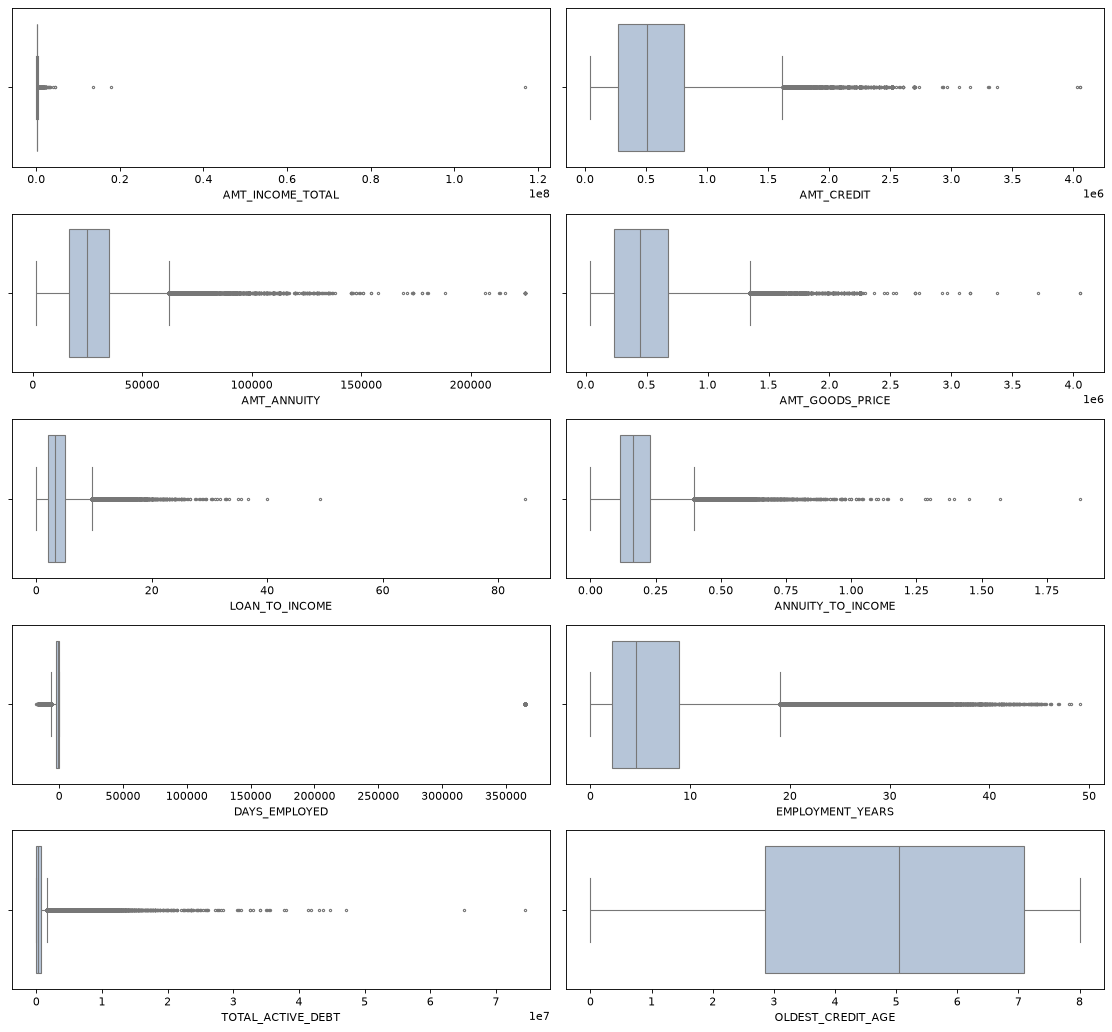

In [75]:
# create boxplots
box_vars = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'LOAN_TO_INCOME',
            'ANNUITY_TO_INCOME', 'DAYS_EMPLOYED', 'EMPLOYMENT_YEARS', 'TOTAL_ACTIVE_DEBT', 'OLDEST_CREDIT_AGE']

row_count = int(np.ceil(len(box_vars) / 2))
fig, axes = plt.subplots(ncols=2, nrows=row_count, figsize=(14, 2.6 * row_count))

for axis, var in zip(fig.axes, box_vars):
    sns.boxplot(ax=axis, x=df[var].dropna(), orient='h', color='lightsteelblue', fliersize=2)
    axis.set_xlabel(var)

plt.tight_layout()
plt.show()

In [76]:
# IQR outlier statistics for continuous and date-relative characteristics
def iqr_outliers(col):
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outside = ((s < lower) | (s > upper)).sum()
    return {'Q1': q1, 'Q3': q3, 'IQR': iqr, 'Lower fence': lower, 'Upper fence': upper,
            'Below lower fence': (s < lower).sum(), 'Above upper fence': (s > upper).sum(),
            'Outlier count': outside, 'Outlier %': outside / len(s) * 100, 'Minimum': s.min(), 'Maximum': s.max()}


iqr_cols = continuous_cols + date_cols
outlier_table = pd.DataFrame({c: iqr_outliers(c) for c in iqr_cols}).T.astype(float)
outlier_table.index.name = 'Characteristic'
outlier_table = outlier_table.sort_values('Outlier %', ascending=False)

print(f'Characteristics assessed: {len(outlier_table)}')
print(f"With at least one IQR outlier: {(outlier_table['Outlier count'] > 0).sum()}")
print(f"With IQR = 0 (fences collapse onto one value): {(outlier_table['IQR'] == 0).sum()}")
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(outlier_table)

Characteristics assessed: 80
With at least one IQR outlier: 73
With IQR = 0 (fences collapse onto one value): 3


,Q1,Q3,IQR,Lower fence,Upper fence,Below lower fence,Above upper fence,Outlier count,Outlier %,Minimum,Maximum
Characteristic,,,,,,,,,,,
DAYS_EMPLOYED,"-2,761.00",-241.00,"2,520.00","-6,541.00","3,539.00","11,933.00","42,230.00","54,163.00",25.39,"-17,912.00","365,243.00"
MAX_REMAINING_DURATION,1.34,4.68,3.34,-3.68,9.70,"2,418.00","27,606.00","30,024.00",20.93,-7.69,85.42
LATEST_BUREAU_UPDATE_AGE,0.02,0.14,0.11,-0.15,0.31,0.00,"35,021.00","35,021.00",19.26,0.00,7.97
TOTAL_REVOLVING_LIMIT,0.00,0.00,0.00,0.00,0.00,0.00,"31,787.00","31,787.00",19.04,0.00,"6,978,830.49"
NONLIVINGAPARTMENTS_AVG,0.00,0.00,0.00,-0.01,0.01,0.00,"10,987.00","10,987.00",16.61,0.00,1.00
NONLIVINGAPARTMENTS_MEDI,0.00,0.00,0.00,-0.01,0.01,0.00,"10,727.00","10,727.00",16.22,0.00,1.00
NONLIVINGAPARTMENTS_MODE,0.00,0.00,0.00,-0.01,0.01,0.00,"10,037.00","10,037.00",15.18,0.00,1.00
NONLIVINGAREA_MODE,0.00,0.02,0.02,-0.03,0.06,0.00,"13,196.00","13,196.00",13.57,0.00,1.00
NONLIVINGAREA_MEDI,0.00,0.03,0.03,-0.04,0.07,0.00,"12,094.00","12,094.00",12.44,0.00,1.00


**Interpretation**

75 of the 82 continuous and date-relative characteristics have at least one IQR outlier, which shows how blunt the 1.5 x IQR rule is for financial data. Three have IQR = 0 (more than half of values are 0), so the fences collapse and **every** non-zero value is flagged. For example, `TOTAL_REVOLVING_LIMIT`, `MAX_DAYS_OVERDUE` and `TOTAL_OVERDUE_AMOUNT` are mostly 0. The flagged observations fall into four different types:

| Type | Examples from the tables above | Meaning |
|---|---|---|
| **Special encoded value** | `DAYS_EMPLOYED`: the 42,230 values of 365243 lie far above the upper fence | Not a measurement; a code that must be handled as its own group |
| **Naturally skewed financial distribution** | `AMT_INCOME_TOTAL`, `AMT_CREDIT`, `TOTAL_ACTIVE_DEBT`, `BUREAU_DEBT_TO_INCOME` | Large incomes and debts are expected in a lending population; flagged only because the distribution is long-tailed |
| **Genuine high-value observation** | `DAYS_EMPLOYED` below the lower fence (11,933 applicants with very long tenure); `MAX_REMAINING_DURATION` above about 10 years | Plausible but unusual; information that should be kept |
| **Potential data-entry error** | `AMT_INCOME_TOTAL` = 117,000,000 against an instalment of about 26,000 (3.3.4) | Implausible against the applicant's other values; needs confirmation |

No outlier is removed or capped here.

### 3.3.4 Data validity observations
The checks below test values against their definitions to see if any outliers are **invalid** . They are reported, not corrected.

In [77]:
# validity checks: (characteristic, check, condition, denominator)
amount_cols = [c for c in df.columns if c.startswith('AMT_') and not c.startswith('AMT_REQ')] + [
    'TOTAL_ACTIVE_DEBT', 'TOTAL_REVOLVING_LIMIT', 'TOTAL_OVERDUE_AMOUNT', 'MAX_HIST_OVERDUE', 'AVG_DEBT_PER_ACTIVE_LOAN']
share_cols = ['ACTIVE_LOAN_RATIO', 'EXISTING_DEBT_SHARE_OF_EXPOSURE', 'CREDIT_HISTORY_AGE_RATIO']
normalised_building = [c for c in building_cols if pd.api.types.is_numeric_dtype(df[c])]
numeric_all = df.select_dtypes(include='number').columns

checks = [
    ('DAYS_EMPLOYED', 'Special code 365243 (about 1,000 years of future employment)', df['DAYS_EMPLOYED'] == 365243),
    ('DAYS_EMPLOYED', 'Other positive values (employment starting after the application)', (df['DAYS_EMPLOYED'] > 0) & (df['DAYS_EMPLOYED'] != 365243)),
    ('CODE_GENDER', "Unrecognised code 'XNA'", df['CODE_GENDER'] == 'XNA'),
    ('ORGANIZATION_TYPE', "Code 'XNA' (no organisation recorded)", df['ORGANIZATION_TYPE'] == 'XNA'),
    ('DAYS_BIRTH, DAYS_REGISTRATION, DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE', 'Positive (event after the application date)',
     (df[['DAYS_BIRTH', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']] > 0).any(axis=1)),
    (f'{len(amount_cols)} monetary amount columns', 'Negative amount', (df[amount_cols] < 0).any(axis=1)),
    ('AGE_YEARS', 'Younger than 18 or older than 100', (df['AGE_YEARS'] < 18) | (df['AGE_YEARS'] > 100)),
    ('EMPLOYMENT_YEARS', 'Employment started before age 14', df['EMPLOYMENT_YEARS'] > df['AGE_YEARS'] - 14),
    ('OWN_CAR_AGE', 'Car older than 50 years', df['OWN_CAR_AGE'] > 50),
    ('CNT_FAM_MEMBERS', 'Fewer family members than children + 1', df['CNT_FAM_MEMBERS'] < df['CNT_CHILDREN'] + 1),
    ('CNT_CHILDREN', 'More than 10 children', df['CNT_CHILDREN'] > 10),
    ('AMT_INCOME_TOTAL', 'Income above 10 million', df['AMT_INCOME_TOTAL'] > 10_000_000),
    ('ANNUITY_TO_INCOME', 'Instalment larger than income (ratio > 1)', df['ANNUITY_TO_INCOME'] > 1),
    ('CREDIT_TO_GOODS_RATIO', 'Credit smaller than goods price (ratio < 1)', df['CREDIT_TO_GOODS_RATIO'] < 1),
    ('LOAN_TO_INCOME', 'Loan more than 20 times income', df['LOAN_TO_INCOME'] > 20),
    ('DEBT_TO_CREDIT_RATIO', 'Debt larger than credit amount (ratio > 1)', df['DEBT_TO_CREDIT_RATIO'] > 1),
    (', '.join(share_cols), 'Share outside 0 to 1', (df[share_cols] < 0).any(axis=1) | (df[share_cols] > 1).any(axis=1)),
    (f'{len(normalised_building)} normalised building columns', 'Value outside 0 to 1',
     (df[normalised_building] < 0).any(axis=1) | (df[normalised_building] > 1).any(axis=1)),
    ('All numeric columns', 'Infinite value', np.isinf(df[numeric_all]).any(axis=1)),
    ('MOST_RECENT_CREDIT_AGE, LATEST_BUREAU_UPDATE_AGE', 'Negative (bureau event after the application date)',
     (df['MOST_RECENT_CREDIT_AGE'] < 0) | (df['LATEST_BUREAU_UPDATE_AGE'] < 0)),
    ('MAX_REMAINING_DURATION', 'Active credit running more than 30 more years', df['MAX_REMAINING_DURATION'] > 30),
    ('MAX_REMAINING_DURATION', 'Active credit past its scheduled end (negative)', df['MAX_REMAINING_DURATION'] < 0),
    ('AMT_REQ_CREDIT_BUREAU_QRT', 'More than 30 enquiries in one 2-month window', df['AMT_REQ_CREDIT_BUREAU_QRT'] > 30),
]

validity = pd.DataFrame([{'Characteristic': c, 'Check': check, 'Applicants flagged': int(cond.sum()),
                          '% of applicants': cond.mean() * 100} for c, check, cond in checks])
validity

,Characteristic,Check,Applicants flagged,% of applicants
0,DAYS_EMPLOYED,"Special code 365243 (about 1,000 years of future employment)",42230,19.7973
1,DAYS_EMPLOYED,Other positive values (employment starting after the application),0,0.0000
2,CODE_GENDER,Unrecognised code 'XNA',4,0.0019
3,ORGANIZATION_TYPE,Code 'XNA' (no organisation recorded),42230,19.7973
4,"DAYS_BIRTH, DAYS_REGISTRATION, DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE",Positive (event after the application date),0,0.0000
5,9 monetary amount columns,Negative amount,0,0.0000
6,AGE_YEARS,Younger than 18 or older than 100,0,0.0000
7,EMPLOYMENT_YEARS,Employment started before age 14,0,0.0000
8,OWN_CAR_AGE,Car older than 50 years,2482,1.1636
9,CNT_FAM_MEMBERS,Fewer family members than children + 1,0,0.0000


In [78]:
# who has the special DAYS_EMPLOYED code, and does it coincide with ORGANIZATION_TYPE = 'XNA'?
display(df.loc[df['DAYS_EMPLOYED'] == 365243, 'NAME_INCOME_TYPE'].value_counts().to_frame('Applicants with DAYS_EMPLOYED = 365243'))
pd.crosstab(df['DAYS_EMPLOYED'] == 365243, df['ORGANIZATION_TYPE'] == 'XNA',
            rownames=['DAYS_EMPLOYED = 365243'], colnames=["ORGANIZATION_TYPE = 'XNA'"])

,Applicants with DAYS_EMPLOYED = 365243
NAME_INCOME_TYPE,
Pensioner,42215
Unemployed,15


ORGANIZATION_TYPE = 'XNA',False,True
DAYS_EMPLOYED = 365243,,
False,171082,0
True,0,42230


In [79]:
# largest incomes and loan-to-income ratios (to judge plausibility)
display(df.nlargest(5, 'AMT_INCOME_TOTAL')[['SK_ID_CURR', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'NAME_INCOME_TYPE', 'OCCUPATION_TYPE', 'TARGET']])
display(df.nlargest(5, 'LOAN_TO_INCOME')[['SK_ID_CURR', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'LOAN_TO_INCOME', 'NAME_INCOME_TYPE', 'TARGET']])

,SK_ID_CURR,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,NAME_INCOME_TYPE,OCCUPATION_TYPE,TARGET
8960,114967,"117,000,000.0000","562,491.0000","26,194.5000",Working,Laborers,1
141167,336147,"18,000,090.0000","675,000.0000","69,295.5000",Commercial associate,NaN,0
171398,385674,"13,500,000.0000","1,400,503.5000","130,945.5000",Commercial associate,NaN,0
71417,219563,"4,500,000.0000","2,250,000.0000","225,000.0000",Working,Managers,0
199407,432980,"4,500,000.0000","1,755,000.0000","61,132.5000",Working,Managers,0


,SK_ID_CURR,AMT_INCOME_TOTAL,AMT_CREDIT,LOAN_TO_INCOME,NAME_INCOME_TYPE,TARGET
14399,124157,"25,650.0000","2,173,500.0000",84.7368,Pensioner,1
24886,141454,"45,000.0000","2,215,224.0000",49.2272,Pensioner,0
156716,361920,"45,000.0000","1,800,000.0000",40.0000,Pensioner,1
177295,395348,"58,500.0000","2,146,500.0000",36.6923,Working,1
109576,283247,"40,500.0000","1,436,850.0000",35.4778,Pensioner,0


**Interpretation**

**Confirmed special or invalid codes**

- `DAYS_EMPLOYED = 365243` for 42,230 applicants (19.8%): 42,215 pensioners and 15 unemployed. It is a placeholder for "not employed", not about 1,000 years of employment.
- `ORGANIZATION_TYPE = 'XNA'` occurs for **exactly the same 42,230 applicants**, so it is a second encoding of the same "no employer" status.
- `CODE_GENDER = 'XNA'` for 4 applicants: an unrecognised code.

**Suspicious, needing confirmation**

- 3 incomes above 10 million. The largest (117 million) belongs to a labourer with an annual instalment of about 26,000, which is very likely an entry error.
- 2,482 applicants (1.2%) with a car older than 50 years.
- One applicant with 261 bureau enquiries in the `AMT_REQ_CREDIT_BUREAU_QRT` window. According to the data dictionary, the enquiry windows are mutually exclusive (for example, the quarter window excludes the last month), so the six counts do not need to increase from hour to year. Even so, 261 enquiries in two months is implausible when 99.9% of applicants have 4 or fewer.
- 146 applicants borrowing more than 20 times their income, and 23 whose instalment exceeds their income.

**Plausible but unusual**

- 3,448 applicants (1.6%) whose bureau debt exceeds the credit amount (interest or over-limit balances).
- 214 loans smaller than the goods price.
- 16,934 applicants with an active credit running more than 30 more years, and 8,446 with an active credit past its scheduled end.
- 5 applicants with more than 10 children.

**Checked and clean**

- No impossible ages, no positive day counts other than the 365243 code, no negative amounts, no shares outside 0-1, and no infinite values.
- No bureau event dated after the application, so there is no sign of look-ahead leakage in the bureau timing.

## 3.4 Categorical Univariate Analysis

### 3.4.1 Automated categorical summary
A **rare category** is defined, for exploratory reporting only, as a category with less than 1% of the non-missing observations.

In [80]:
def categorical_profile(col):
    counts = df[col].value_counts()
    shares = counts / counts.sum() * 100
    rare = shares[shares < 1]
    return {'Variable type': inventory.loc[col, 'Variable classification'],
            'Categories': len(counts),
            'Missing %': df[col].isnull().mean() * 100,
            'Most frequent category': counts.index[0],
            'Frequency': counts.iloc[0],
            'Dominant %': shares.iloc[0],
            'Rare categories (< 1%)': len(rare),
            'Rare categories (examples)': ', '.join(str(x) for x in rare.index[:4])}


categorical_profile_cols = text_cols + binary_cols + discrete_cols
categorical_summary = pd.DataFrame({c: categorical_profile(c) for c in categorical_profile_cols}).T
categorical_summary.index.name = 'Characteristic'
categorical_summary = categorical_summary.sort_values(['Variable type', 'Dominant %'], ascending=[True, False])

print(f'Characteristics profiled: {len(categorical_summary)}')
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(categorical_summary)

Characteristics profiled: 76


,Variable type,Categories,Missing %,Most frequent category,Frequency,Dominant %,Rare categories (< 1%),Rare categories (examples)
Characteristic,,,,,,,,
FLAG_MOBIL,Binary flag,2,0.00,1,213311,100.00,1,0
FLAG_DOCUMENT_12,Binary flag,2,0.00,0,213311,100.00,1,1
FLAG_DOCUMENT_10,Binary flag,2,0.00,0,213305,100.00,1,1
FLAG_DOCUMENT_2,Binary flag,2,0.00,0,213300,99.99,1,1
FLAG_DOCUMENT_4,Binary flag,2,0.00,0,213292,99.99,1,1
FLAG_DOCUMENT_17,Binary flag,2,0.00,0,213288,99.99,1,1
FLAG_DOCUMENT_20,Binary flag,2,0.00,0,213284,99.99,1,1
FLAG_DOCUMENT_7,Binary flag,2,0.00,0,213265,99.98,1,1
FLAG_DOCUMENT_19,Binary flag,2,0.00,0,213252,99.97,1,1


**Interpretation**

- 75 categorical, binary and discrete characteristics were profiled.
- `FLAG_OWN_REALTY` has a single category ('Y'). This is expected, because owning property was a Step 0 segmentation rule; it can carry no information for this segment.
- `ORGANIZATION_TYPE` has 58 categories, 41 of them rare (< 1%). The second most common value is 'XNA' (19.8%), the "no employer" code from 3.3.4.
- `OCCUPATION_TYPE` has 18 categories and is 32.7% missing. Missing occupation is the single largest group (6.4% bad rate, 3.5.4).
- Several discrete bureau counts (`MICROLOAN_COUNT`, `ACTIVE_LOAN_COUNT`, `ACTIVE_CONSUMER_CREDIT_COUNT`) have many rare high values. These are long tails of counts, not separate categories.

### 3.4.2 Bar Charts (Countplots)
Text categories are shown in descending order of frequency; for characteristics with many categories only the 10 most frequent are shown and the number omitted is reported in the title.

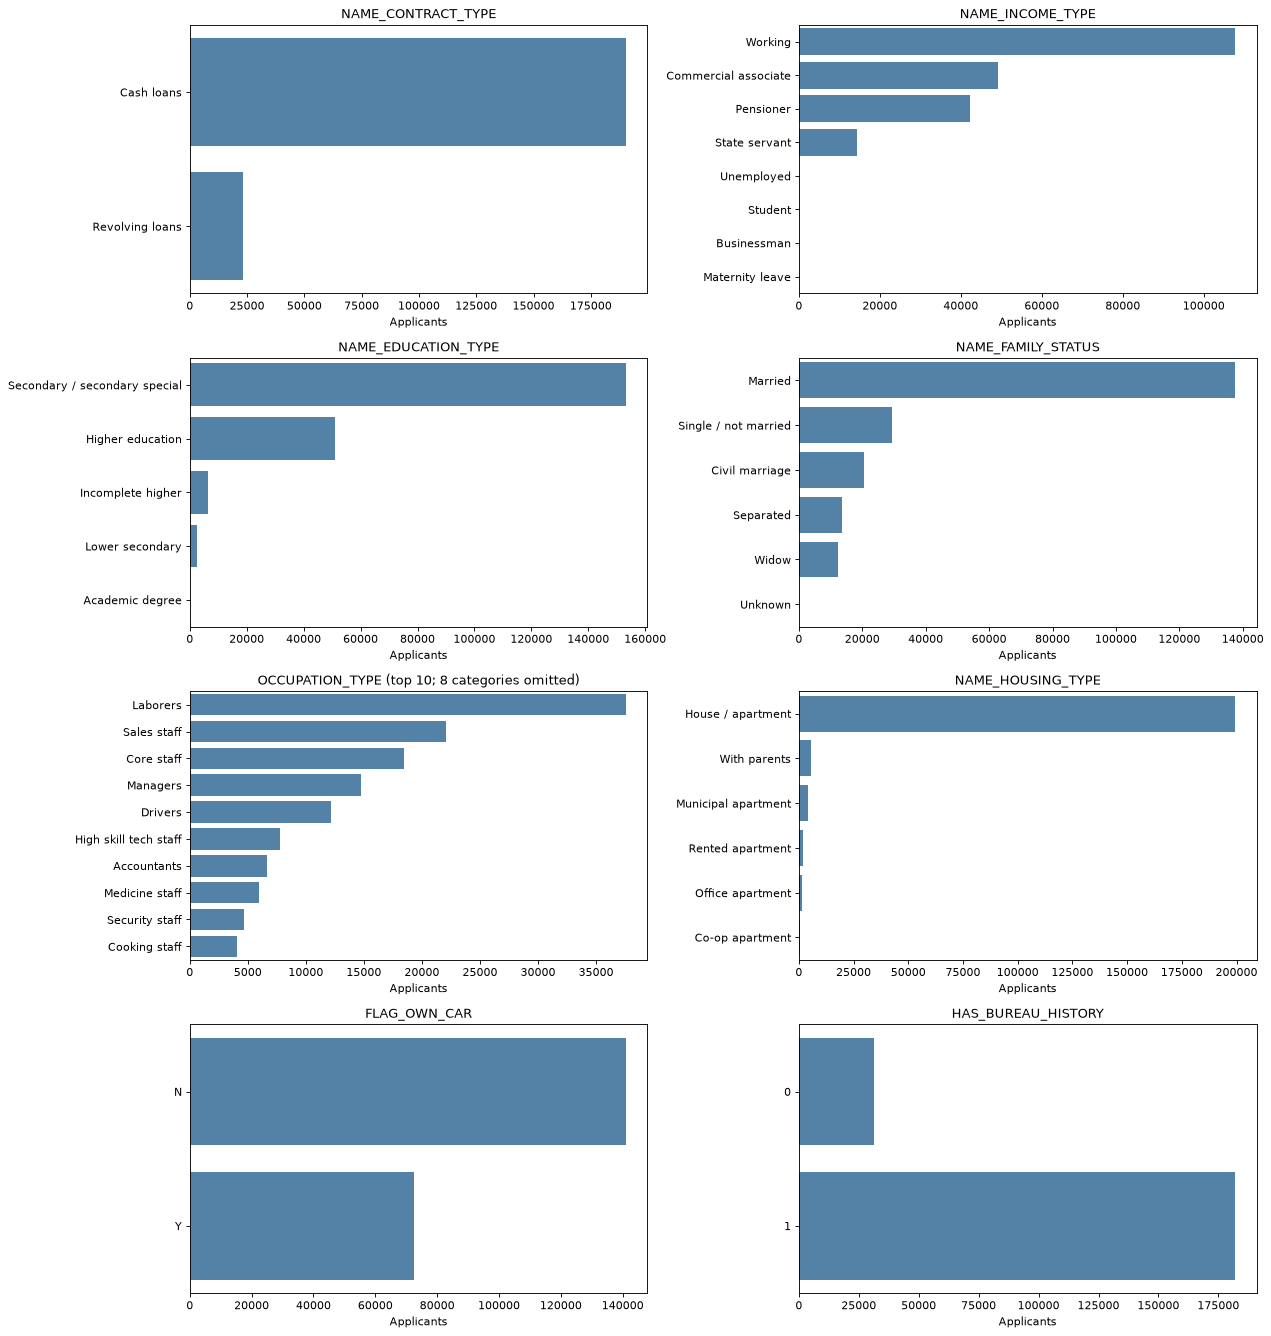

In [33]:
count_vars = ['NAME_CONTRACT_TYPE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
              'OCCUPATION_TYPE', 'NAME_HOUSING_TYPE', 'FLAG_OWN_CAR', 'HAS_BUREAU_HISTORY']
max_shown = 10

row_count = int(np.ceil(len(count_vars) / 2))
fig, axes = plt.subplots(ncols=2, nrows=row_count, figsize=(16, 4.2 * row_count))

for axis, var in zip(fig.axes, count_vars):
    counts = df[var].value_counts()
    order = counts.index[:max_shown]
    omitted = len(counts) - len(order)
    if pd.api.types.is_numeric_dtype(df[var]):
        order = sorted(order)
    shown = df.loc[df[var].isin(order), var]  # temporary selection for plotting
    sns.countplot(ax=axis, y=shown.astype(str), order=[str(o) for o in order], color='steelblue')
    title = var if omitted == 0 else f'{var} (top {max_shown}; {omitted} categories omitted)'
    axis.set_title(title)
    axis.set_xlabel('Applicants')
    axis.set_ylabel('')

plt.tight_layout()
plt.show()

**Interpretation**

- **Loan type:** cash loans dominate `NAME_CONTRACT_TYPE` (89.2%).
- **Income type:** working applicants are the largest group (50.5%), followed by commercial associates (23.0%) and pensioners (19.8%).
- **Education:** secondary education accounts for 71.8%.
- **Family and housing:** most applicants are married, and almost all live in a house or apartment.
- **Assets:** about one third own a car (33.9%).
- **Bureau history:** 85.25% of applicants have it.
- Several characteristics are dominated by one category. That limits how much they can separate goods from bads, and makes the rare categories' bad rates unstable (3.5.4).

### 3.4.3 Low-variance and constant variables

A characteristic where almost every applicant has the same value carries little information for separating goods from bads, and its bad rates in the minority group rest on very few observations. Every characteristic (except the ID) is checked for:

- only one distinct observed value (constant)
- one value accounting for more than 99% of non-missing observations
- binary flags whose minority value is below 1%

These are flagged for review only; nothing is dropped.

In [34]:
def dominant_share(col):
    counts = df[col].value_counts()
    return counts.index[0], counts.iloc[0] / counts.sum() * 100, len(counts)


low_info_rows = []
for col in df.columns.drop('SK_ID_CURR'):
    value, share, n_values = dominant_share(col)
    if n_values == 1:
        reason = 'Constant (one observed value)'
    elif share > 99:
        reason = 'Binary flag with minority < 1%' if inventory.loc[col, 'Variable classification'] == 'Binary flag' else 'One value > 99% of observations'
    elif share > 95:
        reason = 'Watch list: one value 95-99%'
    else:
        continue
    low_info_rows.append({'Characteristic': col, 'Source': inventory.loc[col, 'Source'],
                          'Variable type': inventory.loc[col, 'Variable classification'],
                          'Dominant value': value, 'Dominant %': share,
                          'Minority observations': df[col].notnull().sum() - df[col].value_counts().iloc[0],
                          'Finding': reason})

low_info = pd.DataFrame(low_info_rows).set_index('Characteristic').sort_values('Dominant %', ascending=False)
near_constant = low_info[~low_info['Finding'].str.startswith('Watch')]
print(low_info['Finding'].value_counts().to_string())
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(low_info)

Finding
Binary flag with minority < 1%     18
Watch list: one value 95-99%       13
One value > 99% of observations     2
Constant (one observed value)       1


,Source,Variable type,Dominant value,Dominant %,Minority observations,Finding
Characteristic,,,,,,
FLAG_OWN_REALTY,Original Application Data,Categorical,Y,100.000,0,Constant (one observed value)
FLAG_MOBIL,Original Application Data,Binary flag,1,100.000,1,Binary flag with minority < 1%
FLAG_DOCUMENT_12,Original Application Data,Binary flag,0,100.000,1,Binary flag with minority < 1%
FLAG_DOCUMENT_10,Original Application Data,Binary flag,0,99.997,7,Binary flag with minority < 1%
FLAG_DOCUMENT_2,Original Application Data,Binary flag,0,99.994,12,Binary flag with minority < 1%
FLAG_DOCUMENT_4,Original Application Data,Binary flag,0,99.991,20,Binary flag with minority < 1%
FLAG_DOCUMENT_17,Original Application Data,Binary flag,0,99.989,24,Binary flag with minority < 1%
FLAG_DOCUMENT_20,Original Application Data,Binary flag,0,99.987,28,Binary flag with minority < 1%
FLAG_DOCUMENT_7,Original Application Data,Binary flag,0,99.978,47,Binary flag with minority < 1%


**Interpretation**

- 21 characteristics are constant or near-constant (one value > 99%), with another 13 on the 95-99% watch list.
  - **Constant:** `FLAG_OWN_REALTY`, a result of the segmentation.
  - **Binary flags with a minority below 1%:** 18 flags. `FLAG_MOBIL` and `FLAG_DOCUMENT_12` each have a single applicant in the minority. Fifteen `FLAG_DOCUMENT_*` flags have fewer than 1,000.
  - **Discrete counts with one value > 99%:** `AMT_REQ_CREDIT_BUREAU_DAY` and `_HOUR` (almost always 0).
- With so few minority observations, any bad rate for the minority group is statistically unreliable. These characteristics are flagged for review in data preparation, not dropped here.
- Several bureau delinquency characteristics are on the watch list: `MAX_DAYS_OVERDUE` and `OVERDUE_LOAN_COUNT` are 98.7% zero, and `ADVERSE_STATUS_COUNT` is 98.0% zero. Their minority groups are still large in absolute terms (2,326 and 3,605 applicants), so low variance alone does not make them uninformative (3.5.4).

## 3.5 Bivariate Analysis Against TARGET

Bivariate analysis checks whether the distribution of a characteristic differs between good (`TARGET = 0`) and bad (`TARGET = 1`) applicants.

All `TARGET`-based results in this section are **exploratory**, calculated on the full dataset. Formal binning, WOE/IV and characteristic selection must later be done on the training data only.

### 3.5.1 Good versus bad borrowers

,Applicants,Percent
Good (TARGET = 0),196329,92.0384
Bad (TARGET = 1),16983,7.9616


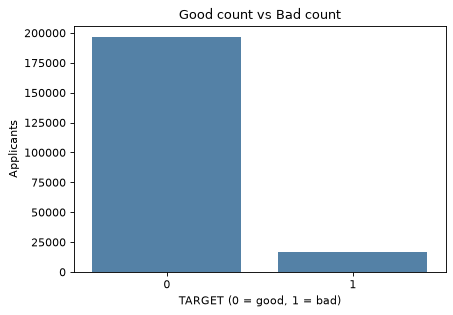

In [35]:
# goods vs bads
target_table = pd.DataFrame({'Applicants': [n_goods, n_bads],
                             'Percent': [n_goods / len(df) * 100, n_bads / len(df) * 100]},
                            index=['Good (TARGET = 0)', 'Bad (TARGET = 1)'])
display(target_table)

plt.figure(figsize=(6, 4))
sns.countplot(x=df['TARGET'], color='steelblue')
plt.title('Good count vs Bad count')
plt.xlabel('TARGET (0 = good, 1 = bad)')
plt.ylabel('Applicants')
plt.show()

**Interpretation**

The data is imbalanced: 92.04% good and 7.96% bad, about 11.6 goods for every bad

### 3.5.2 Continuous characteristics - KDE plots
With `common_norm=False` each curve integrates to 1, so the **shapes** of the good and bad distributions are compared directly. A KDE curve shows where values are concentrated within each group; it is **not** a probability of default.

A characteristic is plotted only if it has at least 20 distinct values and no single value accounts for more than half of the observations; otherwise a KDE would mostly draw a spike and is skipped with the reason shown. For skewed characteristics a second view is restricted to the 1st-99th percentile range.

In [36]:
kde_candidates = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'LOAN_TO_INCOME',
                  'AGE_YEARS', 'EMPLOYMENT_YEARS', 'TOTAL_ACTIVE_DEBT']

kde_vars, kde_skipped = [], []
for var in kde_candidates:
    s = df[var].dropna()
    top_share = s.value_counts(normalize=True).iloc[0] * 100
    if s.nunique() < 20:
        kde_skipped.append((var, f'Only {s.nunique()} distinct values'))
    elif top_share > 50:
        kde_skipped.append((var, f'{top_share:.1f}% of non-missing values equal {s.value_counts().index[0]:g}'))
    else:
        kde_vars.append(var)

print('Plotted:', kde_vars)

Plotted: ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'LOAN_TO_INCOME', 'AGE_YEARS', 'EMPLOYMENT_YEARS', 'TOTAL_ACTIVE_DEBT']


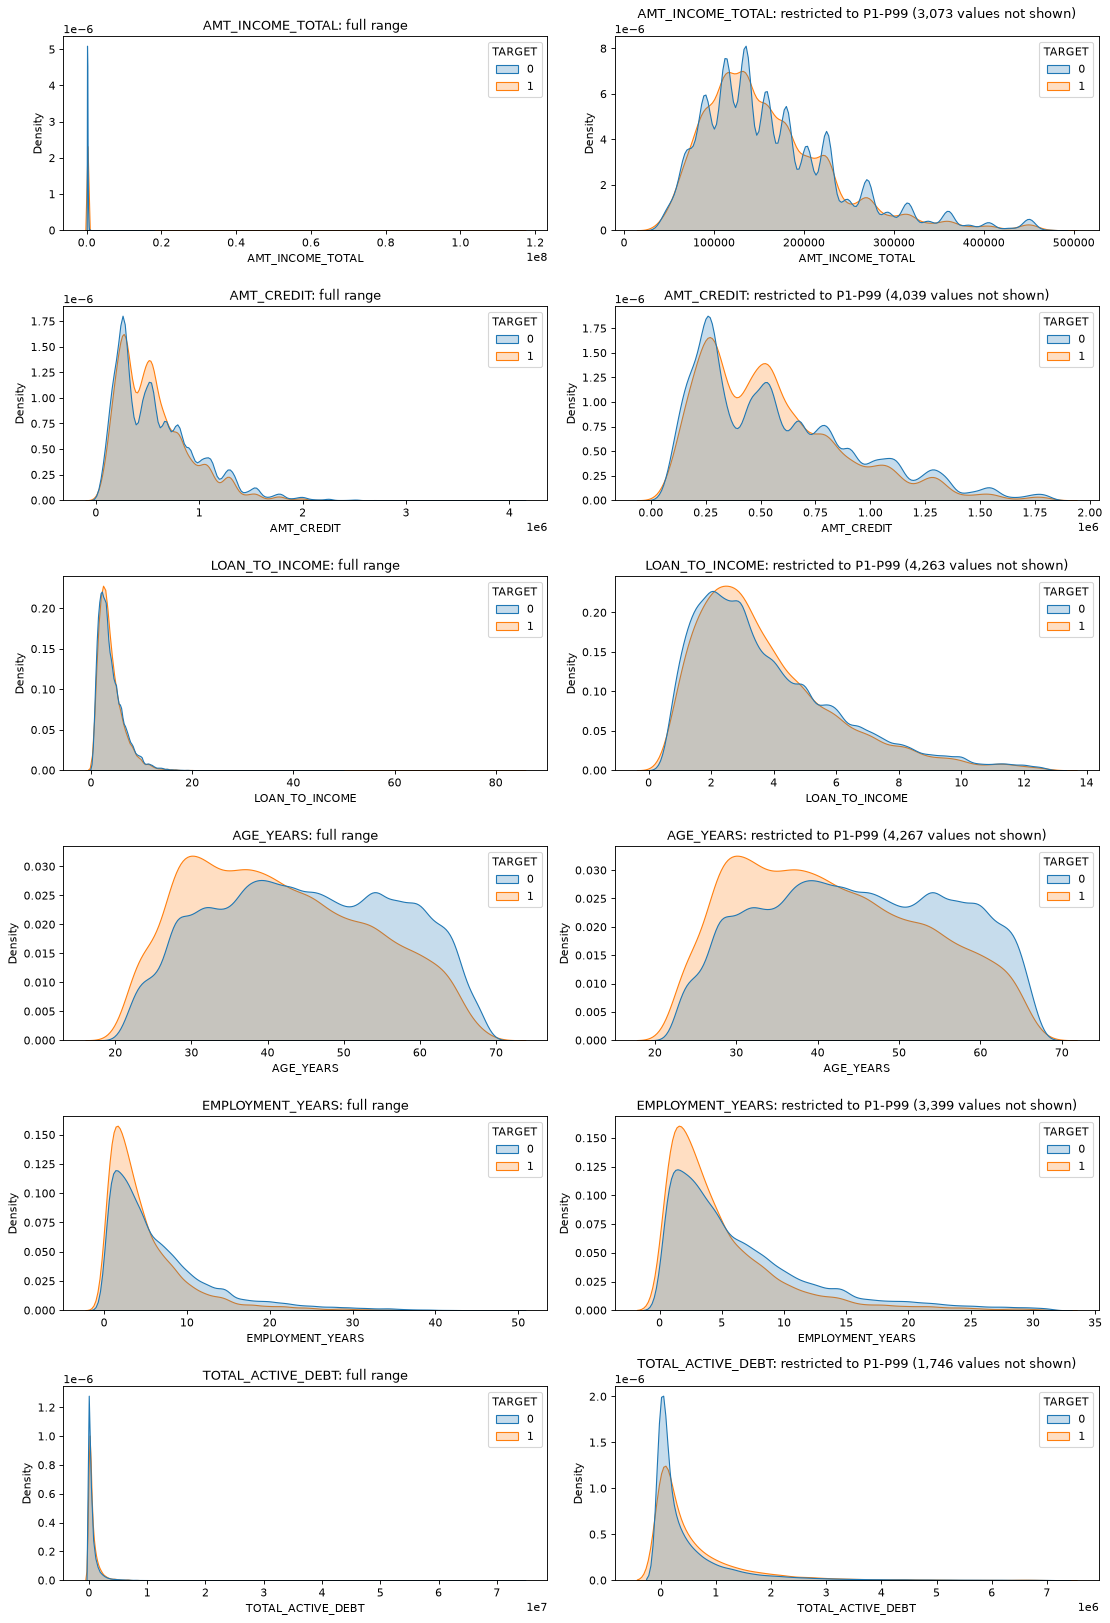

In [37]:
# good vs bad KDE: full range (left) and 1st-99th percentile view (right)
fig, axes = plt.subplots(len(kde_vars), 2, figsize=(14, 3.4 * len(kde_vars)))

for row, var in zip(axes, kde_vars):
    plot_data = df[[var, 'TARGET']].dropna()  # temporary copy for plotting
    sns.kdeplot(ax=row[0], data=plot_data, x=var, hue='TARGET', fill=True, common_norm=False)
    row[0].set_title(f'{var}: full range')

    p1, p99 = plot_data[var].quantile([0.01, 0.99])
    inner = plot_data[(plot_data[var] >= p1) & (plot_data[var] <= p99)]
    sns.kdeplot(ax=row[1], data=inner, x=var, hue='TARGET', fill=True, common_norm=False)
    row[1].set_title(f'{var}: restricted to P1-P99 ({len(plot_data) - len(inner):,} values not shown)')

plt.tight_layout()
plt.show()

In [38]:
# numbers behind the KDE plots: summary statistics by TARGET
kde_stats = []
for var in kde_vars:
    good = df.loc[df['TARGET'] == 0, var].dropna()
    bad = df.loc[df['TARGET'] == 1, var].dropna()
    kde_stats.append({'Characteristic': var, 'Median (good)': good.median(), 'Median (bad)': bad.median(),
                      'Mean (good)': good.mean(), 'Mean (bad)': bad.mean(),
                      'Median difference % of good median': (bad.median() - good.median()) / abs(good.median()) * 100 if good.median() != 0 else np.nan,
                      'Missing % (good)': df.loc[df['TARGET'] == 0, var].isnull().mean() * 100,
                      'Missing % (bad)': df.loc[df['TARGET'] == 1, var].isnull().mean() * 100})
kde_stats = pd.DataFrame(kde_stats).set_index('Characteristic')
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(kde_stats.sort_values('Median difference % of good median', key=abs, ascending=False))

,Median (good),Median (bad),Mean (good),Mean (bad),Median difference % of good median,Missing % (good),Missing % (bad)
Characteristic,,,,,,,
TOTAL_ACTIVE_DEBT,"175,729.500","273,712.500","652,521.254","707,332.776",55.758,17.888,21.510
EMPLOYMENT_YEARS,4.695,3.370,6.818,5.017,-28.222,20.360,13.296
AGE_YEARS,44.920,40.372,45.135,41.595,-10.124,0.000,0.000
AMT_INCOME_TOTAL,"148,500.000","144,000.000","169,228.710","169,625.177",-3.030,0.000,0.000
AMT_CREDIT,"508,495.500","497,520.000","591,410.535","555,136.157",-2.158,0.000,0.000
LOAN_TO_INCOME,3.160,3.172,3.874,3.827,0.388,0.000,0.000


**Interpretation**
- **Age and employment.** Bads are younger (median age 40.4 vs 44.9) and have shorter employment (median 3.4 vs 4.7 years). The bad curve for `EMPLOYMENT_YEARS` peaks earlier and higher.
- **Bureau characteristics.** Bads have a *higher* active debt (median 273,713 vs 175,730)
- **Little visible difference:** `AMT_INCOME_TOTAL`, `AMT_CREDIT` and `LOAN_TO_INCOME` almost overlap (median differences of 0.4% to 3.9%). On their own, the size of the loan and the income do not separate goods from bads in this segment.
- **Extreme tails.** The full-range plots for income, debt and the ratios are squeezed into a spike by a few extreme values (for example the 117 million income), so only the P1-P99 views can be interpreted.
- A KDE shows where values are concentrated within each group; it does not give the probability of default at a value.

### 3.5.3 Categorical characteristics - bar charts (countplots)
Because only 8% of applicants are bad, the bad bars are always much shorter; raw counts show **where** applicants are, while the normalised charts in 3.5.4 show the **bad rate**. Missing values are not drawn here (their bad rates are shown in 3.5.4). For count characteristics only the 0-10 range is drawn; the number of applicants above it is given in the title.

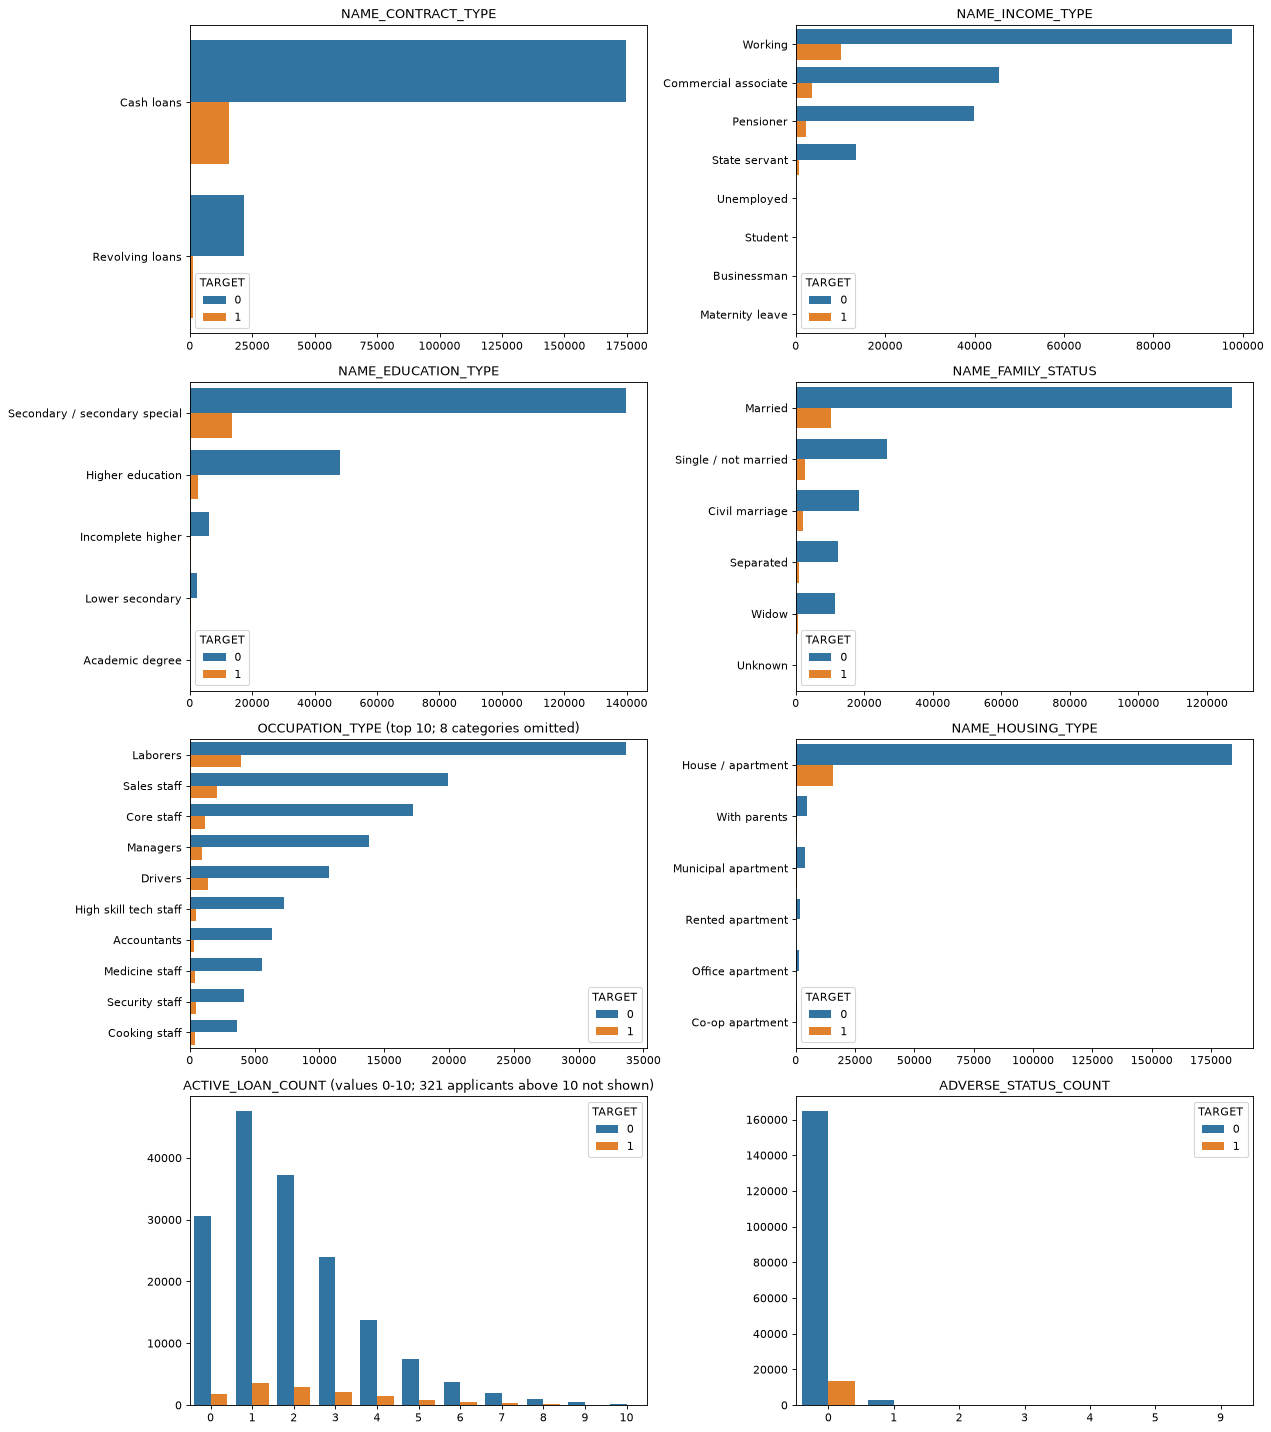

In [39]:
countplot_vars = ['NAME_CONTRACT_TYPE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
                  'OCCUPATION_TYPE', 'NAME_HOUSING_TYPE', 'ACTIVE_LOAN_COUNT', 'ADVERSE_STATUS_COUNT']

row_count = int(np.ceil(len(countplot_vars) / 2))
fig, axes = plt.subplots(ncols=2, nrows=row_count, figsize=(16, 4.5 * row_count))

for axis, var in zip(fig.axes, countplot_vars):
    if pd.api.types.is_numeric_dtype(df[var]) and df[var].nunique() > 11:
        keep = df[var] <= 10
        order = sorted(df.loc[keep, var].dropna().unique())
        title = f'{var} (values 0-10; {(df[var] > 10).sum():,} applicants above 10 not shown)'
    else:
        counts = df[var].value_counts()
        order = counts.index[:10] if not pd.api.types.is_numeric_dtype(df[var]) else sorted(counts.index)
        keep = df[var].isin(order)
        title = var if len(counts) <= 10 else f'{var} (top 10; {len(counts) - 10} categories omitted)'
    shown = df.loc[keep, [var, 'TARGET']]  # temporary selection for plotting
    if pd.api.types.is_numeric_dtype(df[var]):
        sns.countplot(ax=axis, x=shown[var].astype(int).astype(str), hue=shown['TARGET'],
                      order=[str(int(o)) for o in order])
    else:
        sns.countplot(ax=axis, y=shown[var], hue=shown['TARGET'], order=order)
    axis.set_title(title)
    axis.set_xlabel('')
    axis.set_ylabel('')

plt.tight_layout()
plt.show()

**Interpretation**

The countplots show where applicants are concentrated. Because only 8% are bad, the bad bars are short everywhere, and the largest groups have the most bads simply because of their size. For example, working applicants and secondary education have the most bads in absolute terms. Whether a group is *riskier* is answered by the bad rates in 3.5.4, not by these counts.

### 3.5.4 Normalised stacked bar charts
The share of goods and bads in each category are shown as a 100% stacked bar. Missing values are shown as their own category ("Missing") on a temporary series.

**Small samples:** a bad rate estimated from 1,000 applicants at an 8% rate has a 95% margin of error of roughly +/-1.7 percentage points, and the margin grows quickly below that. Categories with fewer than 1,000 applicants are therefore marked as small samples.

In [87]:
overall_bad_rate = df['TARGET'].mean() * 100
small_sample = 1000

def display_categories(var, max_categories=12):
    # Temporary series: missing shown as its own category
    # Convert to string to avoid mixed str/float sorting errors
    s = df[var].astype(object).where(df[var].notnull(), 'Missing')
    s = s.astype(str)

    counts = s.value_counts()

    if pd.api.types.is_numeric_dtype(df[var]):
        # Sort numeric categories numerically
        values = sorted(
            [v for v in counts.index if v != 'Missing'],
            key=float)

        order = values[:max_categories]

        if 'Missing' in counts.index:
            order.append('Missing')
    else:
        # Sort categorical variables by frequency
        order = counts.index[:max_categories].tolist()

    omitted = len(counts) - len(order)

    return s, order, omitted


def good_bad_table(var, max_categories=12):
    s, order, omitted = display_categories(var, max_categories)

    # Count goods and bads per category
    table = pd.crosstab(s, df['TARGET'])

    # Preserve category order and ensure both TARGET classes exist
    table = table.reindex(
        index=order,
        columns=[0, 1],
        fill_value=0)

    table.columns = ['Goods', 'Bads']

    table.insert(
        0,
        'Applicants',
        table['Goods'] + table['Bads'])

    table['Bad rate %'] = (
        table['Bads'] / table['Applicants'] * 100)

    table['Small sample'] = np.where(
        table['Applicants'] < small_sample,
        'Yes',
        '')

    table.index.name = var

    return table, omitted


def stacked_bar(var, axis, max_categories=12):
    s, order, omitted = display_categories(var, max_categories)

    # Normalised good/bad shares per category
    df_bivariate = pd.crosstab(
        s,
        df['TARGET'],
        normalize='index')

    # Preserve category order and ensure both classes exist
    df_bivariate = df_bivariate.reindex(
        index=order,
        columns=[0, 1],
        fill_value=0)

    df_bivariate.columns = ['Good', 'Bad']

    # Plot stacked bars
    df_bivariate.plot(
        ax=axis,
        kind='bar',
        stacked=True,
        color=['steelblue', 'indianred'],
        width=0.8)

    # Overall good share reference line
    axis.axhline(
        1 - overall_bad_rate / 100,
        color='black',
        linestyle='--',
        linewidth=1,
        label='Overall good share')

    axis.set_ylim(0.5, 1.0)

    axis.set_title(
        var if omitted == 0
        else f'{var} ({omitted} categories omitted)')

    axis.set_xlabel('')

    axis.set_xticklabels(
        [str(x)[:25] for x in order],
        rotation=45,
        ha='right')

    axis.legend(
        bbox_to_anchor=(1.0, 1.0),
        fontsize=8)

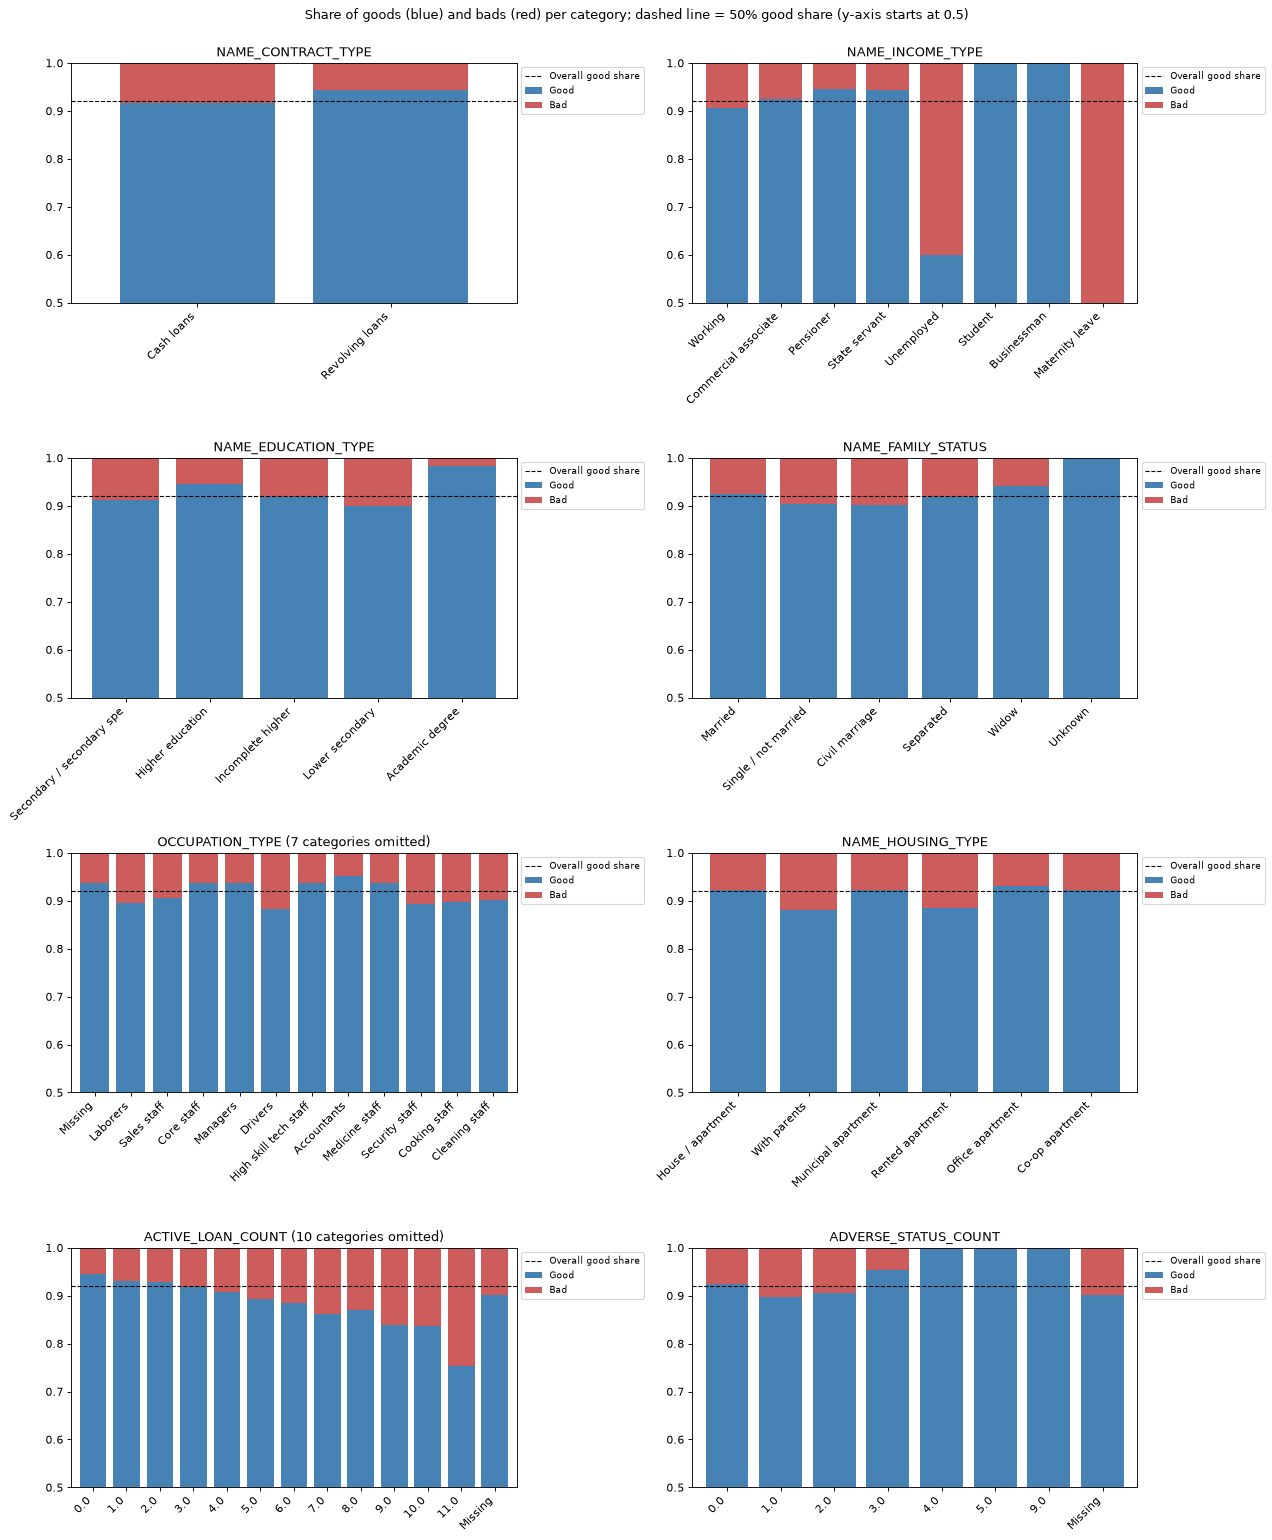

In [89]:
stacked_vars = ['NAME_CONTRACT_TYPE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
                  'OCCUPATION_TYPE', 'NAME_HOUSING_TYPE', 'ACTIVE_LOAN_COUNT', 'ADVERSE_STATUS_COUNT']

row_count = int(np.ceil(len(stacked_vars) / 2))
fig, axes = plt.subplots(ncols=2, nrows=row_count, figsize=(16, 4.8 * row_count))
for axis, var in zip(fig.axes, stacked_vars):
    stacked_bar(var, axis)
plt.suptitle('Share of goods (blue) and bads (red) per category; dashed line = 50% good share (y-axis starts at 0.5)', y=1.0)
plt.tight_layout()
plt.show()

In [90]:
# counts and bad rates behind each stacked bar chart
for var in stacked_vars:
    table, omitted = good_bad_table(var)
    print(f'\n{var}' + (f'  ({omitted} further categories not shown)' if omitted else ''))
    with pd.option_context('display.float_format', '{:,.2f}'.format):
        display(table)


NAME_CONTRACT_TYPE


,Applicants,Goods,Bads,Bad rate %,Small sample
NAME_CONTRACT_TYPE,,,,,
Cash loans,190207,174506,15701,8.25,
Revolving loans,23105,21823,1282,5.55,



NAME_INCOME_TYPE


,Applicants,Goods,Bads,Bad rate %,Small sample
NAME_INCOME_TYPE,,,,,
Working,107651,97463,10188,9.46,
Commercial associate,49107,45384,3723,7.58,
Pensioner,42224,39972,2252,5.33,
State servant,14293,13481,812,5.68,
Unemployed,15,9,6,40.00,Yes
Student,10,10,0,0.00,Yes
Businessman,8,8,0,0.00,Yes
Maternity leave,4,2,2,50.00,Yes



NAME_EDUCATION_TYPE


,Applicants,Goods,Bads,Bad rate %,Small sample
NAME_EDUCATION_TYPE,,,,,
Secondary / secondary special,153133,139673,13460,8.79,
Higher education,50996,48257,2739,5.37,
Incomplete higher,6561,6031,530,8.08,
Lower secondary,2507,2255,252,10.05,
Academic degree,115,113,2,1.74,Yes


... (6 outputs left out)


ACTIVE_LOAN_COUNT  (10 further categories not shown)


,Applicants,Goods,Bads,Bad rate %,Small sample
ACTIVE_LOAN_COUNT,,,,,
0.0,32300,30516,1784,5.52,
1.0,51117,47557,3560,6.96,
2.0,40128,37224,2904,7.24,
3.0,26062,23915,2147,8.24,
4.0,15143,13733,1410,9.31,
5.0,8361,7474,887,10.61,
6.0,4204,3720,484,11.51,
7.0,2207,1903,304,13.77,
8.0,1145,996,149,13.01,



ADVERSE_STATUS_COUNT


,Applicants,Goods,Bads,Bad rate %,Small sample
ADVERSE_STATUS_COUNT,,,,,
0.0,178236,164742,13494,7.57,
1.0,3345,3004,341,10.19,
2.0,232,210,22,9.48,Yes
3.0,22,21,1,4.55,Yes
4.0,3,3,0,0.00,Yes
5.0,2,2,0,0.00,Yes
9.0,1,1,0,0.00,Yes
Missing,31471,28346,3125,9.93,


In [93]:
# HAS_BUREAU_HISTORY: compare with the reference bad rates
bureau_table, _ = good_bad_table('HAS_BUREAU_HISTORY')
display(bureau_table)

reference_rates = pd.DataFrame({
    'Reference bad rate %': [7.62, 9.93],
    'Calculated bad rate %': bureau_table.loc[
        ['1', '0'], 'Bad rate %'
    ].round(2).values
}, index=['With bureau history', 'Without bureau history'])

reference_rates['Match'] = (
    reference_rates['Reference bad rate %'] ==
    reference_rates['Calculated bad rate %'])

display(reference_rates)

,Applicants,Goods,Bads,Bad rate %,Small sample
HAS_BUREAU_HISTORY,,,,,
0,31471,28346,3125,9.9298,
1,181841,167983,13858,7.6209,


,Reference bad rate %,Calculated bad rate %,Match
With bureau history,7.6200,7.6200,True
Without bureau history,9.9300,9.9300,True


#### Automated bad-rate scan across all categorical and discrete characteristics

To make sure no characteristic is overlooked, the same table is computed for every categorical, binary and discrete characteristic. For each, the highest and lowest bad-rate categories with **at least 1,000 applicants** are reported, together with how many small categories have extreme bad rates.

In [94]:
scan_rows = []
for var in categorical_profile_cols:
    if var == 'TARGET':
        continue
    s = df[var].astype(object).where(df[var].notnull(), 'Missing')
    table = pd.crosstab(s, df['TARGET'])
    applicants = table.sum(axis=1)
    bad_rate = table[1] / applicants * 100
    large = bad_rate[applicants >= small_sample]
    small = bad_rate[applicants < small_sample]
    if len(large) < 2:
        continue
    scan_rows.append({'Characteristic': var,
                      'Highest bad-rate category': large.idxmax(), 'Highest bad rate %': large.max(),
                      'n (highest)': applicants[large.idxmax()],
                      'Lowest bad-rate category': large.idxmin(), 'Lowest bad rate %': large.min(),
                      'n (lowest)': applicants[large.idxmin()],
                      'Spread (pp)': large.max() - large.min(),
                      'Small categories with 0% or >= 2x overall bad rate': ((small == 0) | (small >= 2 * overall_bad_rate)).sum()})

bad_rate_scan = pd.DataFrame(scan_rows).set_index('Characteristic').sort_values('Spread (pp)', ascending=False)
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(bad_rate_scan.head(25))
print(f'Characteristics scanned: {len(bad_rate_scan)}')

,Highest bad-rate category,Highest bad rate %,n (highest),Lowest bad-rate category,Lowest bad rate %,n (lowest),Spread (pp),Small categories with 0% or >= 2x overall bad rate
Characteristic,,,,,,,,
OCCUPATION_TYPE,Low-skill Laborers,16.64,1418,Accountants,4.76,6659,11.88,0
MICROLOAN_COUNT,1.00,18.55,1326,0.00,7.46,179329,11.09,26
ACTIVE_LOAN_COUNT,7.00,13.77,2207,0.00,5.52,32300,8.25,12
ORGANIZATION_TYPE,Construction,12.20,4567,Police,4.83,1471,7.37,2
ACTIVE_CREDIT_CARD_COUNT,5.00,13.17,1435,0.00,6.51,80437,6.66,8
REGION_RATING_CLIENT_W_CITY,3,11.17,30145,1,4.82,23287,6.35,0
OVERDUE_LOAN_COUNT,1.00,13.87,2178,0.00,7.52,179515,6.34,5
REGION_RATING_CLIENT,3,10.88,33284,1,4.86,22000,6.02,0
HOUR_APPR_PROCESS_START,6,11.27,4295,19,5.73,1675,5.54,1


Characteristics scanned: 57


In [95]:
# small categories with extreme bad rates (where apparent patterns may be noise)
small_rows = []
for var in categorical_profile_cols:
    if var == 'TARGET':
        continue
    s = df[var].astype(object).where(df[var].notnull(), 'Missing')
    table = pd.crosstab(s, df['TARGET'])
    applicants = table.sum(axis=1)
    bad_rate = table[1] / applicants * 100
    for cat in applicants.index[(applicants < small_sample) & ((bad_rate == 0) | (bad_rate >= 2 * overall_bad_rate))]:
        small_rows.append({'Characteristic': var, 'Category': cat, 'Applicants': applicants[cat],
                           'Bads': table.loc[cat, 1], 'Bad rate %': bad_rate[cat]})
small_extremes = pd.DataFrame(small_rows).sort_values('Applicants', ascending=False)
print(f'Small categories (< {small_sample:,} applicants) with 0% or >= 2x overall bad rate: {len(small_extremes)}')
print(f"  of which with fewer than 30 applicants: {(small_extremes['Applicants'] < 30).sum()}")
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(small_extremes.head(20))

Small categories (< 1,000 applicants) with 0% or >= 2x overall bad rate: 161
  of which with fewer than 30 applicants: 142


,Characteristic,Category,Applicants,Bads,Bad rate %
7,ORGANIZATION_TYPE,Transport: type 3,835,141,16.89
87,ACTIVE_LOAN_COUNT,9.00,559,90,16.10
135,MICROLOAN_COUNT,2.00,469,79,16.84
88,ACTIVE_LOAN_COUNT,10.00,294,48,16.33
121,ACTIVE_CREDIT_CARD_COUNT,7.00,289,51,17.65
136,MICROLOAN_COUNT,3.00,221,42,19.00
113,ACTIVE_CONSUMER_CREDIT_COUNT,7.00,173,34,19.65
89,ACTIVE_LOAN_COUNT,11.00,154,38,24.68
137,MICROLOAN_COUNT,4.00,143,33,23.08
122,ACTIVE_CREDIT_CARD_COUNT,8.00,113,18,15.93


**Interpretation**
- **Bureau history.** Applicants without bureau history have a 9.93% bad rate versus 7.62% with history, matching the reference values. This does not mean that having no bureau record causes default. The group may differ in other ways (for example, younger applicants or thinner credit files), and the missing bureau values are themselves informative.
- **Clear gradients with large samples:**
  - `ACTIVE_LOAN_COUNT` rises steadily from 5.52% (no active loan, n = 32,300) to 13.77% (7 active loans, n = 2,207).
  - `OVERDUE_LOAN_COUNT` goes from 7.52% at 0 to 13.87% at 1 (n = 2,178).
  - `REGION_RATING_CLIENT` goes from 4.86% (rating 1) to 10.88% (rating 3).
  - `NAME_EDUCATION_TYPE` goes from 5.37% (higher education) to 10.05% (lower secondary).
- **Higher-risk groups with at least 1,000 applicants:**
  - Low-skill labourers (16.64%, n = 1,418) and drivers (11.68%)
  - Applicants living with parents (11.98%) or in rented apartments (11.55%)
  - One microloan (18.55%, n = 1,326)
- **Lower-risk groups:** pensioners (5.33%), revolving loans (5.55%), accountants (4.76%) and the 365243 special-code group (5.35%).
- **Missing as its own category.** Missing occupation (n = 69,712) has a below-average bad rate of 6.38%, consistent with many of these applicants being pensioners. Missing values can carry information and should not simply be imputed.
- **Unreliable small samples:**
  - Of 161 small categories with 0% or at least double the overall bad rate, 142 have fewer than 30 applicants.
  - Examples: unemployed (40%, n = 15), maternity leave (50%, n = 4), `OVERDUE_LOAN_COUNT` = 5 (100%, n = 2) and academic degree (1.74%, n = 115).

## 3.6 Correlation Analysis

### 3.6.1 Calculate correlations
`SK_ID_CURR` and `TARGET` are excluded from the feature-to-feature matrix. The 0/1 flags are analysed separately. Pandas uses pairwise complete observations, so each correlation is based on the applicants where both values are present.

In [48]:
# Correlation matrix for numeric characteristics
corr_cols = [c for c in numeric_profile_cols if df[c].nunique() > 1]
cor = df[corr_cols].corr()
print(f'Correlation matrix: {cor.shape[0]} x {cor.shape[1]} characteristics')

# separate matrix for the binary flags (constant flags excluded because their correlation is undefined)
binary_numeric = [c for c in binary_cols if pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 1]
binary_cor = df[binary_numeric].corr()
print(f'Binary-flag correlation matrix: {binary_cor.shape[0]} x {binary_cor.shape[1]} flags')

Correlation matrix: 105 x 105 characteristics
Binary-flag correlation matrix: 34 x 34 flags


### 3.6.2 Identify correlated pairs

All pairs with |r| > 0.50 are listed with a rule-based explanation of **why** they might be related:

- **Mathematical**: one is calculated from the other, or both are calculated from the same input (formulas from the `01` and `03` notebooks)
- **Shared source**: the same underlying field summarised differently (e.g. building `_AVG` / `_MODE` / `_MEDI`, 30- vs 60-day social-circle windows, aggregations of the same bureau records)
- **Financial**: values that move together for business reasons (e.g. loan amount, goods price and instalment)
- **Related, requires review**: no structural link identified

No characteristic is removed here.

In [49]:
# inputs of each engineered characteristic (from the 01 and 03 notebook formulas)
formula_inputs = {
    'AGE_YEARS': ['DAYS_BIRTH'], 'EMPLOYMENT_YEARS': ['DAYS_EMPLOYED'], 'FLAG_DAYS_EMPLOYED_SPECIAL': ['DAYS_EMPLOYED'],
    'LOAN_TO_INCOME': ['AMT_CREDIT', 'AMT_INCOME_TOTAL'], 'ANNUITY_TO_INCOME': ['AMT_ANNUITY', 'AMT_INCOME_TOTAL'],
    'CREDIT_TO_GOODS_RATIO': ['AMT_CREDIT', 'AMT_GOODS_PRICE'], 'INCOME_PER_FAMILY_MEMBER': ['AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS'],
    'BUREAU_DEBT_TO_INCOME': ['TOTAL_ACTIVE_DEBT', 'AMT_INCOME_TOTAL'],
    'TOTAL_EXPOSURE_TO_INCOME': ['TOTAL_ACTIVE_DEBT', 'AMT_CREDIT', 'AMT_INCOME_TOTAL'],
    'AVG_DEBT_PER_ACTIVE_LOAN': ['TOTAL_ACTIVE_DEBT', 'ACTIVE_LOAN_COUNT'],
    'CREDIT_HISTORY_AGE_RATIO': ['OLDEST_CREDIT_AGE', 'AGE_YEARS'],
    'ACTIVE_LOANS_PER_INCOME': ['ACTIVE_LOAN_COUNT', 'AMT_INCOME_TOTAL'],
    'EXISTING_DEBT_SHARE_OF_EXPOSURE': ['TOTAL_ACTIVE_DEBT', 'AMT_CREDIT'],
    'ACTIVE_LOAN_RATIO': ['ACTIVE_LOAN_COUNT', 'BUREAU_LOAN_COUNT'],
    'DEBT_TO_CREDIT_RATIO': ['TOTAL_ACTIVE_DEBT'],
}


def all_inputs(col):
    found = set()
    for i in formula_inputs.get(col, []):
        found |= {i} | all_inputs(i)
    return found


def building_stem(col):
    for suffix in building_suffixes:
        if col.endswith(suffix):
            return col[:-len(suffix)]
    return None


def interpret_pair(a, b):
    inputs_a, inputs_b = all_inputs(a), all_inputs(b)
    if a in inputs_b:
        return f'Mathematical: {b} is calculated from {a}'
    if b in inputs_a:
        return f'Mathematical: {a} is calculated from {b}'
    if inputs_a & inputs_b:
        return f"Mathematical: both calculated from {', '.join(sorted(inputs_a & inputs_b))}"
    if building_stem(a) and building_stem(a) == building_stem(b):
        return 'Shared source: same building measure (AVG / MODE / MEDI)'
    if a in building_cols and b in building_cols:
        return 'Shared source: related building attributes'
    if 'SOCIAL_CIRCLE' in a and 'SOCIAL_CIRCLE' in b:
        return 'Shared source: social-circle counts over 30- and 60-day windows'
    if a.startswith('REGION_RATING') and b.startswith('REGION_RATING'):
        return 'Shared source: region rating with and without city'
    if a.startswith('AMT_REQ_CREDIT_BUREAU') and b.startswith('AMT_REQ_CREDIT_BUREAU'):
        return 'Shared source: bureau enquiries over different windows'
    if a in bureau_cols and b in bureau_cols:
        return 'Shared source: aggregated from the same bureau records'
    if {a, b} <= {'AMT_CREDIT', 'AMT_GOODS_PRICE', 'AMT_ANNUITY'}:
        return 'Financial: loan amount, goods price and instalment move together'
    if {a, b} == {'CNT_CHILDREN', 'CNT_FAM_MEMBERS'}:
        return 'Financial/demographic: family size includes children'
    return 'Related, requires review'


def correlated_pairs(matrix, threshold):
    upper = matrix.where(np.triu(np.ones(matrix.shape, dtype=bool), k=1)).stack()
    pairs = upper[upper.abs() > threshold].reset_index()
    pairs.columns = ['Characteristic A', 'Characteristic B', 'Correlation']
    pairs['Absolute Correlation'] = pairs['Correlation'].abs()
    pairs['Interpretation'] = [interpret_pair(a, b) for a, b in zip(pairs['Characteristic A'], pairs['Characteristic B'])]
    return pairs.sort_values('Absolute Correlation', ascending=False).reset_index(drop=True)


corr_pairs = correlated_pairs(cor, 0.5)
pair_counts = pd.DataFrame({'Pairs': [(corr_pairs['Absolute Correlation'] > t).sum() for t in [0.5, 0.7, 0.9]]},
                           index=['|r| > 0.50', '|r| > 0.70', '|r| > 0.90'])
display(pair_counts)

# summarise by interpretation type
corr_pairs['Relationship type'] = corr_pairs['Interpretation'].str.split(':').str[0]
display(pd.crosstab(corr_pairs['Relationship type'], pd.cut(corr_pairs['Absolute Correlation'].clip(upper=1.0), [0.5, 0.7, 0.9, 1.0],
                    labels=['0.50-0.70', '0.70-0.90', '> 0.90']), margins=True, margins_name='Total'))

,Pairs
|r| > 0.50,357
|r| > 0.70,138
|r| > 0.90,65


Absolute Correlation,0.50-0.70,0.70-0.90,> 0.90,Total
Relationship type,,,,
Financial,0,2,1,3
Financial/demographic,0,1,0,1
Mathematical,5,8,3,16
"Related, requires review",12,0,0,12
Shared source,202,62,61,325
Total,219,73,65,357


In [50]:
# pairs excluding the building AVG / MODE / MEDI duplicates (shown in summary below)
same_building = corr_pairs['Interpretation'].str.contains('same building measure')
print(f'Building AVG / MODE / MEDI pairs: {same_building.sum()} '
      f"(|r| from {corr_pairs.loc[same_building, 'Absolute Correlation'].min():.3f} to {corr_pairs.loc[same_building, 'Absolute Correlation'].max():.3f})")
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(corr_pairs.loc[~same_building].drop(columns='Relationship type'))

Building AVG / MODE / MEDI pairs: 42 (|r| from 0.959 to 0.999)


,Characteristic A,Characteristic B,Correlation,Absolute Correlation,Interpretation
0,DAYS_EMPLOYED,EMPLOYMENT_YEARS,-1.000,1.000,Mathematical: EMPLOYMENT_YEARS is calculated from DAYS_EMPLOYED
1,DAYS_BIRTH,AGE_YEARS,-1.000,1.000,Mathematical: AGE_YEARS is calculated from DAYS_BIRTH
2,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.999,0.999,Shared source: social-circle counts over 30- and 60-day windows
21,AMT_CREDIT,AMT_GOODS_PRICE,0.987,0.987,"Financial: loan amount, goods price and instalment move together"
46,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,0.951,0.951,Shared source: region rating with and without city
...,...,...,...,...,...
352,LANDAREA_MODE,LIVINGAREA_MEDI,0.502,0.502,Shared source: related building attributes
353,ELEVATORS_AVG,FLOORSMIN_MODE,0.501,0.501,Shared source: related building attributes
354,FLOORSMIN_MODE,ELEVATORS_MEDI,0.501,0.501,Shared source: related building attributes
355,TOTAL_EXPOSURE_TO_INCOME,EXISTING_DEBT_SHARE_OF_EXPOSURE,0.501,0.501,"Mathematical: both calculated from AMT_CREDIT, TOTAL_ACTIVE_DEBT"


In [51]:
# binary flags with |r| > 0.50
binary_pairs = correlated_pairs(binary_cor, 0.5).drop(columns='Interpretation')
print(f'Binary-flag pairs with |r| > 0.50: {len(binary_pairs)}')
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(binary_pairs)

Binary-flag pairs with |r| > 0.50: 5


,Characteristic A,Characteristic B,Correlation,Absolute Correlation
0,FLAG_EMP_PHONE,FLAG_DAYS_EMPLOYED_SPECIAL,-1.000,1.000
1,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,0.880,0.880
2,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,0.843,0.843
3,FLAG_DOCUMENT_6,FLAG_DAYS_EMPLOYED_SPECIAL,0.589,0.589
4,FLAG_EMP_PHONE,FLAG_DOCUMENT_6,-0.589,0.589


**Interpretation**

362 pairs have |r| > 0.50, 140 have |r| > 0.70 and 67 have |r| > 0.90. Almost all are explained by how the data was built.

**Shared source**

- Most pairs above 0.50 involve the building variables. All 42 `_AVG` / `_MODE` / `_MEDI` pairs correlate at 0.959-0.999, so each building measure is present three times.
- `OBS_30` / `OBS_60_CNT_SOCIAL_CIRCLE` (0.999) and `DEF_30` / `DEF_60` (0.86) are overlapping time windows.
- `REGION_RATING_CLIENT` / `_W_CITY` (0.95) is the same rating with and without city.
- `ACTIVE_LOAN_COUNT` correlates with its components `ACTIVE_CREDIT_CARD_COUNT` (0.77) and `ACTIVE_CONSUMER_CREDIT_COUNT` (0.76).

**Mathematical**

- `DAYS_EMPLOYED` / `EMPLOYMENT_YEARS` and `DAYS_BIRTH` / `AGE_YEARS` (-1.00) are unit conversions.
- `EMPLOYMENT_AGE_RATIO` / `EMPLOYMENT_YEARS` (0.96).
- `BUREAU_DEBT_TO_INCOME` / `TOTAL_EXPOSURE_TO_INCOME` (0.94).
- `AMT_INCOME_TOTAL` / `INCOME_PER_FAMILY_MEMBER` (0.89).
- `OLDEST_CREDIT_AGE` / `CREDIT_HISTORY_AGE_RATIO` (0.85).
- `TOTAL_ACTIVE_DEBT` with the debt ratios (0.71-0.84).
- `LOAN_TO_INCOME` / `ANNUITY_TO_INCOME` (0.79), which share the income denominator.

**Financial**

- `AMT_CREDIT` / `AMT_GOODS_PRICE` (0.99): the loan usually equals the price of the goods.
- `AMT_ANNUITY` with credit and goods price (0.78).
- `CNT_CHILDREN` / `CNT_FAM_MEMBERS` (0.88).

**Binary flags**

- `FLAG_EMP_PHONE` is the exact inverse of `FLAG_DAYS_EMPLOYED_SPECIAL` (r = -1.000). Applicants without an employer have no employer phone, so these two flags carry identical information.
- The region-vs-work and city-vs-work mismatch flags are strongly related (0.88 and 0.84).

**Pairs needing review**

No pair above 0.70 is left unexplained. The 13 pairs marked "requires review" are all between 0.50 and 0.70.

Nothing is removed here. The Week 9 rule (drop the weaker of each pair with |r| > 0.8) is for data preparation, using training data.

### 3.6.3 Correlation heatmaps

One heatmap of all numeric columns would be unreadable, so the `sns.heatmap` approach is applied to four smaller groups. A diverging colour scale centred on 0 is used so positive (red) and negative (blue) correlations are easy to tell apart. For building variables only the `_AVG` versions are shown, since the `_MODE` and `_MEDI` versions duplicate them (3.6.2).

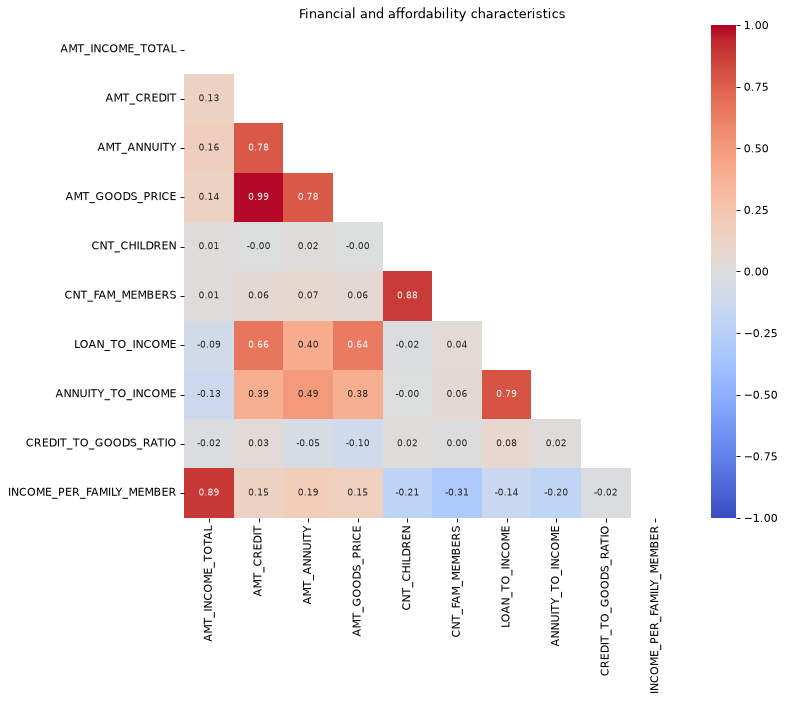

In [52]:
def corr_heatmap(cols, title, size=(10, 8), annot_size=8):
    cols = [c for c in cols if c in cor.columns]
    mask = np.triu(np.ones((len(cols), len(cols)), dtype=bool), k=0)
    fig, ax = plt.subplots(figsize=size)
    sns.heatmap(cor.loc[cols, cols], mask=mask, xticklabels=cols, yticklabels=cols, annot=True, fmt='.2f',
                annot_kws={'size': annot_size}, cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=ax)
    ax.set_title(title)
    plt.show()


heatmap_financial = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS',
                     'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_GOODS_RATIO', 'INCOME_PER_FAMILY_MEMBER', 'CREDIT_TO_ANNUITY_RATIO']
corr_heatmap(heatmap_financial, 'Financial and affordability characteristics')

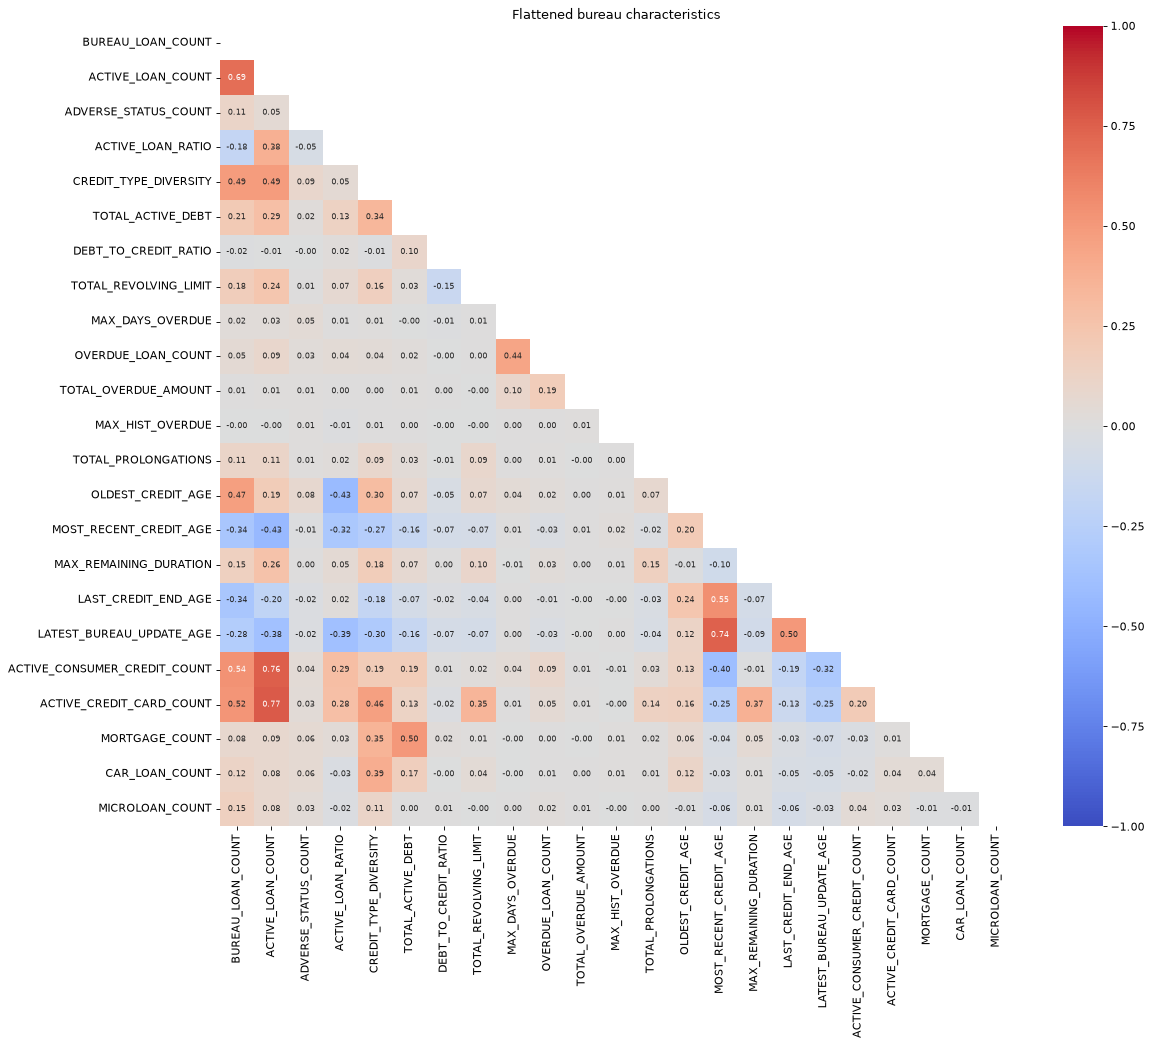

In [53]:
corr_heatmap(bureau_cols, 'Flattened bureau characteristics', size=(16, 13), annot_size=7)

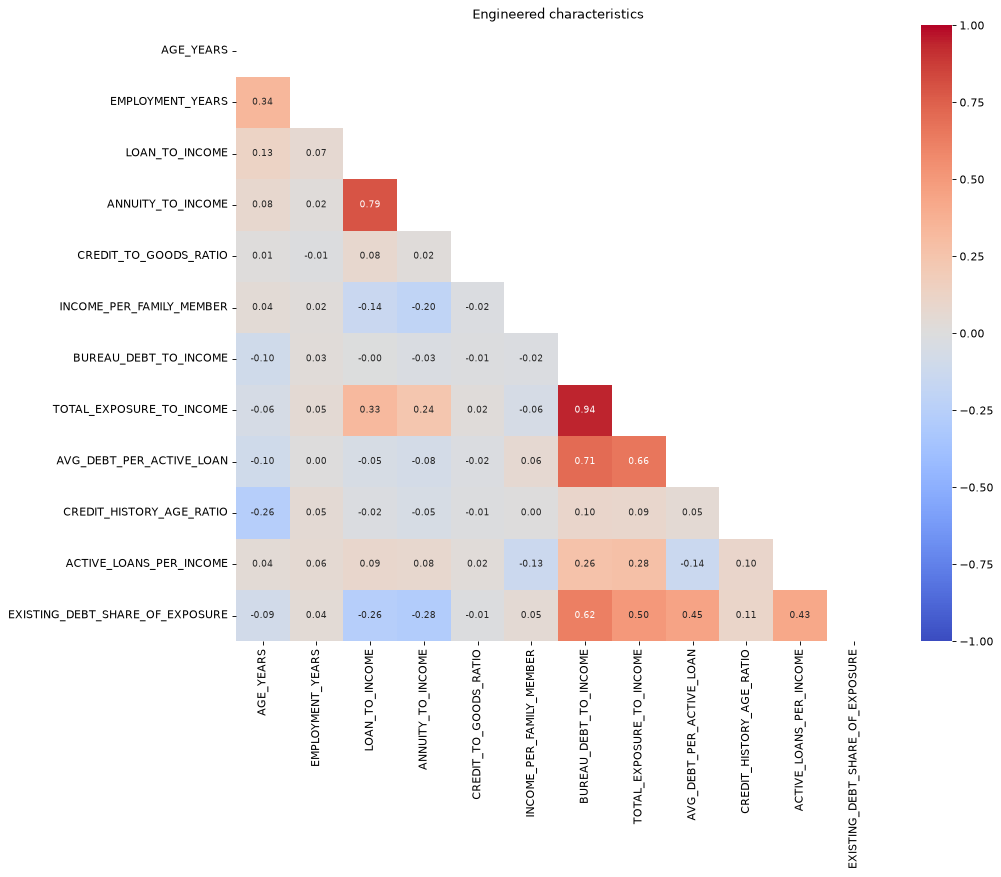

In [54]:
engineered_numeric = [c for c in new_app_features + new_cross_features if c in cor.columns]
corr_heatmap(engineered_numeric, 'Engineered characteristics', size=(13, 10))

**Interpretation**

- **Financial:**
  - `AMT_CREDIT`, `AMT_GOODS_PRICE` and `AMT_ANNUITY` form one tightly related block.
  - Each ratio correlates mainly with the amount in its own formula.
  - `AMT_INCOME_TOTAL` is only weakly related to the loan amounts (r = 0.13 to 0.16), which is why loan-to-income ratios add information beyond the raw amounts. Correlation is sensitive to the 117 million income outlier, so this is re-checked after outlier treatment.
  - `INCOME_PER_FAMILY_MEMBER` is negatively related to household size (-0.31 with `CNT_FAM_MEMBERS`), as its formula implies.
- **Bureau:**
  - The count characteristics form a block, led by `ACTIVE_LOAN_COUNT` and its credit card (0.77) and consumer credit (0.76) components.
  - No delinquency characteristic correlates above 0.7 with an exposure characteristic (3.6.2), so delinquency measures a different dimension of risk.
  - `MOST_RECENT_CREDIT_AGE` and `LATEST_BUREAU_UPDATE_AGE` are related (0.74).
- **Engineered:**
  - The pairs built from shared inputs are visible: `EMPLOYMENT_YEARS` / `EMPLOYMENT_AGE_RATIO` (0.96), and `BUREAU_DEBT_TO_INCOME` with `TOTAL_EXPOSURE_TO_INCOME` (0.94) and `AVG_DEBT_PER_ACTIVE_LOAN` (0.71).
  - No other pair of engineered characteristics exceeds 0.7.

### 3.6.4 Exploratory correlation with TARGET

Correlation between each numeric characteristic and the 0/1 `TARGET` (for a 0/1 flag this is the point-biserial correlation). Each value uses the applicants where the characteristic is present.

- A **positive** correlation means higher values tend to go with bad outcomes; a **negative** correlation means higher values tend to go with good outcomes.
- Correlation does not establish causation.
- Correlation measures only straight-line relationships, so a characteristic with a U-shaped or threshold relationship can show a small r.
- This ranking is **not** the feature-selection decision; that is done later with WOE/IV on training data.

,Correlation with TARGET,Applicants used,Source,Absolute Correlation
Characteristic,,,,
EXT_SOURCE_1,-0.1568,90183,Original Application Data,0.1568
AGE_YEARS,-0.0804,213312,Engineered application feature,0.0804
DAYS_BIRTH,0.0804,213312,Original Application Data,0.0804
EMPLOYMENT_YEARS,-0.0772,171082,Engineered application feature,0.0772
ACTIVE_LOAN_RATIO,0.0770,181841,Flattened Bureau Data,0.0770
OLDEST_CREDIT_AGE,-0.0749,181841,Flattened Bureau Data,0.0749
CREDIT_TO_GOODS_RATIO,0.0736,213089,Engineered application feature,0.0736
ACTIVE_LOAN_COUNT,0.0702,181841,Flattened Bureau Data,0.0702
ACTIVE_LOANS_PER_INCOME,0.0617,181841,Engineered cross-dataset feature,0.0617


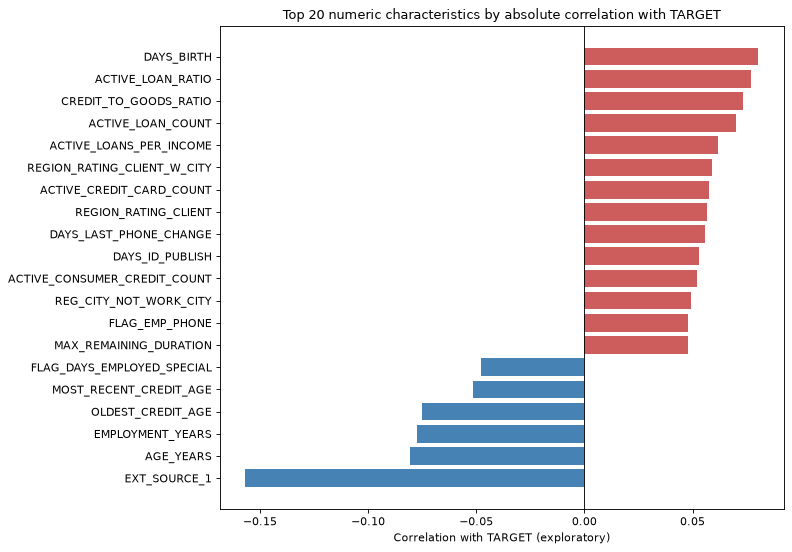

Characteristics with |r| >= 0.05: 16 of 139
Largest |r|: 0.1568 (EXT_SOURCE_1)


In [55]:
target_corr_cols = [c for c in numeric_profile_cols + binary_numeric if c != 'TARGET']
target_corr = pd.DataFrame({
    'Correlation with TARGET': [df[c].corr(df['TARGET']) for c in target_corr_cols],
    'Applicants used': [df[c].notnull().sum() for c in target_corr_cols],
    'Source': inventory.loc[target_corr_cols, 'Source'].values,
}, index=pd.Index(target_corr_cols, name='Characteristic'))
target_corr['Absolute Correlation'] = target_corr['Correlation with TARGET'].abs()
target_corr = target_corr.sort_values('Absolute Correlation', ascending=False)

with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(target_corr.head(25))

top20 = target_corr.head(20).sort_values('Correlation with TARGET')
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top20.index, top20['Correlation with TARGET'], color=np.where(top20['Correlation with TARGET'] > 0, 'indianred', 'steelblue'))
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Correlation with TARGET (exploratory)')
ax.set_title('Top 20 numeric characteristics by absolute correlation with TARGET')
plt.tight_layout()
plt.show()

print(f"Characteristics with |r| >= 0.05: {(target_corr['Absolute Correlation'] >= 0.05).sum()} of {len(target_corr)}")
print(f"Largest |r|: {target_corr['Absolute Correlation'].max():.4f} ({target_corr.index[0]})")

**Interpretation (exploratory)**

- All linear relationships with `TARGET` are **weak**. The strongest is `EXT_SOURCE_1` (r = -0.157), and only 17 of 141 numeric characteristics reach |r| >= 0.05. No single characteristic predicts default on its own, which is typical of credit data and is why a scorecard combines several characteristics.
- **Negative r** (higher values go with good outcomes): `EXT_SOURCE_1`, `AGE_YEARS`, `EMPLOYMENT_YEARS`, `OLDEST_CREDIT_AGE` and `EMPLOYMENT_AGE_RATIO`. Older, longer-employed applicants with longer credit histories tend to be better risks.
- **Positive r** (higher values go with bad outcomes): `ACTIVE_LOAN_RATIO`, `ACTIVE_LOAN_COUNT`, `CREDIT_TO_GOODS_RATIO`, `ACTIVE_LOANS_PER_INCOME` and the region ratings. More active credit and borrowing above the goods price go with higher risk.
- `DAYS_BIRTH` and `AGE_YEARS` appear with opposite signs and the same size because they are the same information in different units.
- Correlation only captures straight-line relationships. Characteristics with threshold effects, such as `OVERDUE_LOAN_COUNT` (3.5.4), can show a small r but a large bad-rate difference. The WOE/IV analysis on training data will measure this properly.

## 3.7 Comprehensive EDA Findings Register

The register below is **generated from the tables calculated above**, so every finding has evidence behind it. Related findings are grouped (for example, the 47 building variables) to keep the register readable.

Severity shows the **priority for investigation in the data-preparation stage**, not whether a characteristic must be removed:

| Category | High | Medium | Low |
|---|---|---|---|
| High missingness | > 60% missing | 40-60% missing, or > 20% missing among applicants with bureau history | - |
| Structural missingness | - | Missing exactly because bureau data is absent | - |
| Suspected invalid value | >= 5% of applicants | 0.5% to 5% | < 0.5% |
| Extreme values | Full range >= 10x the P1-P99 range | 3x to 10x | - |
| High skewness | - | Skewness > 10 | Skewness 2-10 (grouped) |
| Low variance | Constant | One value > 99% | - |
| High correlation | - | |r| > 0.90 | |r| 0.70-0.90 (grouped) |
| Unusual good/bad pattern | - | Category (>= 1,000 applicants) with bad rate >= 1.5x or <= 0.5x overall | Small-sample extremes (grouped) |
| Potential leakage | Evidence of post-application information | - | Checked, none found |
| Fair-lending concern | - | Protected or sensitive characteristic | - |

In [99]:
register = []

def add(characteristic, category, observation, evidence, severity, action):
    register.append({'Characteristic': characteristic, 'EDA category': category, 'Observation': observation,
                     'Evidence': evidence, 'Severity': severity, 'Recommended next investigation': action})

def list_cols(cols, limit=6):
    cols = list(cols)
    return ', '.join(cols[:limit]) + (f' (+{len(cols) - limit} more)' if len(cols) > limit else '')

# --- high missingness (building variables grouped)
high_missing = missing_table[missing_table['Missing %'] > 40]
bld = high_missing[high_missing.index.isin(building_cols)]
if len(bld):
    add(f'{len(bld)} building variables', 'High missingness', 'Building/property fields mostly unreported',
        f"{bld['Missing %'].min():.1f}% to {bld['Missing %'].max():.1f}% missing", 'High' if bld['Missing %'].max() > 60 else 'Medium',
        'Assess whether missingness itself is informative; decide whether any building field is usable')
for col, row in high_missing[~high_missing.index.isin(building_cols)].iterrows():
    add(col, 'High missingness', 'Large share of values missing', f"{row['Missing %']:.1f}% missing",
        'High' if row['Missing %'] > 60 else 'Medium', 'Investigate mechanism; consider a missing indicator or a separate WOE bin')
for col, row in bureau_missing[bureau_missing['Missing % (with bureau history)'] > 20].iterrows():
    if col not in high_missing.index:
        add(col, 'High missingness', 'Missing even among applicants with bureau history',
            f"{row['Missing % (with bureau history)']:.1f}% missing within bureau applicants", 'Medium',
            'Separate "no bureau" from "not applicable" (e.g. no active loan) before treatment')

# --- structural missingness
structural = bureau_missing[bureau_missing['Missing % (without bureau history)'] == 100]
add(f'{len(structural)} bureau and cross-dataset characteristics', 'Structural missingness',
    'Missing for every applicant without bureau history',
    f"{(~has_bureau).sum():,} applicants ({(~has_bureau).mean() * 100:.2f}%) have no bureau record; bad rate "
    f"{bureau_table.loc['0', 'Bad rate %']:.2f}% vs {bureau_table.loc['1', 'Bad rate %']:.2f}% with history",
    'Medium', 'Treat "no bureau history" as its own group rather than imputing values')

# --- suspected invalid values
for _, row in validity[validity['Applicants flagged'] > 0].iterrows():
    sev = 'High' if row['% of applicants'] >= 5 else ('Medium' if row['% of applicants'] >= 0.5 else 'Low')
    add(row['Characteristic'], 'Suspected invalid value', row['Check'],
        f"{row['Applicants flagged']:,} applicants ({row['% of applicants']:.2f}%)", sev,
        'Confirm meaning with the data owner; decide on recoding or exclusion in data preparation')

# --- extreme values (building variables grouped)
extreme_rows = numeric_summary[numeric_summary['Flags'].str.contains('Extreme range')]
extreme_building = extreme_rows[extreme_rows.index.isin(building_cols)]
if len(extreme_building):
    add(f'{len(extreme_building)} building variables', 'Extreme values', 'Normalised 0-1 fields with a long tail up to 1',
        list_cols(extreme_building.index, 4), 'Medium', 'Only relevant if building fields are kept')
for col, row in extreme_rows[~extreme_rows.index.isin(building_cols)].iterrows():
    s = df[col]
    p1, p99 = s.quantile([0.01, 0.99])
    ratio = (row['Max'] - row['Min']) / (p99 - p1)
    out_pct = outlier_table.loc[col, 'Outlier %'] if col in outlier_table.index else np.nan
    add(col, 'Extreme values', 'Range stretched by a few extreme observations',
        f"max {row['Max']:,.4g} vs P99 {row['P99']:,.4g}; range = {ratio:.1f}x P1-P99 range"
        + (f'; {out_pct:.1f}% IQR outliers' if pd.notnull(out_pct) else ''),
        'High' if ratio >= 10 else 'Medium', 'Check extremes for plausibility; evaluate capping or binning of tails')

# --- high skewness
very_skewed = numeric_summary[numeric_summary['Skewness'].abs() > 10]
skewed_building = very_skewed[very_skewed.index.isin(building_cols)]
if len(skewed_building):
    add(f'{len(skewed_building)} building variables', 'High skewness', 'Very heavy tail',
        f"|skewness| {skewed_building['Skewness'].abs().min():.1f} to {skewed_building['Skewness'].abs().max():.1f}: {list_cols(skewed_building.index, 3)}",
        'Medium', 'Only relevant if building fields are kept')
for col, row in very_skewed[~very_skewed.index.isin(building_cols)].iterrows():
    add(col, 'High skewness', 'Very heavy tail', f"skewness {row['Skewness']:.1f}", 'Medium',
        'Use quantile-based bins rather than equal-width bins')
moderately_skewed = numeric_summary[(numeric_summary['Skewness'].abs() > 2) & (numeric_summary['Skewness'].abs() <= 10)]
add(list_cols(moderately_skewed.index), 'High skewness', f'{len(moderately_skewed)} characteristics with |skewness| 2-10',
    'See 3.3.1 numerical summary', 'Low', 'Quantile-based fine classing will handle these')

# --- low variance (document flags grouped)
constant = near_constant[near_constant['Finding'].str.startswith('Constant')]
for col, row in constant.iterrows():
    add(col, 'Low variance', 'Only one observed value', f"100% = {row['Dominant value']}", 'High', 'Confirm and exclude from modelling candidates')
dominant = near_constant[~near_constant['Finding'].str.startswith('Constant')]
doc_flags = dominant[dominant.index.str.startswith('FLAG_DOCUMENT')]
if len(doc_flags):
    add(f'{len(doc_flags)} FLAG_DOCUMENT flags', 'Low variance', 'Minority value below 1%',
        f"dominant value {doc_flags['Dominant %'].min():.2f}% to {doc_flags['Dominant %'].max():.2f}%; minority counts "
        f"{doc_flags['Minority observations'].min():,} to {doc_flags['Minority observations'].max():,}",
        'Medium', 'Check whether minority groups are large enough for stable bad rates')
for col, row in dominant[~dominant.index.str.startswith('FLAG_DOCUMENT')].iterrows():
    add(col, 'Low variance', row['Finding'], f"{row['Dominant %']:.2f}% = {row['Dominant value']}; {row['Minority observations']:,} other values",
        'Medium', 'Check whether minority groups are large enough for stable bad rates')

# --- high correlation
very_high = corr_pairs[corr_pairs['Absolute Correlation'] > 0.9]
vh_building = very_high[very_high['Interpretation'].str.contains('building')]
if len(vh_building):
    add(f'{len(vh_building)} building variable pairs', 'High correlation', 'AVG / MODE / MEDI versions of the same measure and related building fields',
        f"|r| {vh_building['Absolute Correlation'].min():.3f} to {vh_building['Absolute Correlation'].max():.3f}", 'Medium',
        'Keep at most one version per measure if building fields are used')
for _, row in very_high[~very_high['Interpretation'].str.contains('building')].iterrows():
    add(f"{row['Characteristic A']} / {row['Characteristic B']}", 'High correlation', row['Interpretation'],
        f"r = {row['Correlation']:.3f}", 'Medium', 'Compare predictive strength (IV) and keep the more interpretable one')
mid_high = corr_pairs[(corr_pairs['Absolute Correlation'] > 0.7) & (corr_pairs['Absolute Correlation'] <= 0.9)]
add(f'{len(mid_high)} pairs', 'High correlation', 'Pairs with |r| between 0.70 and 0.90',
    f"{(mid_high['Relationship type'] == 'Mathematical').sum()} mathematical, {(mid_high['Relationship type'] == 'Shared source').sum()} shared source",
    'Low', 'Review alongside IV results (Week 9 correlation > 0.8 rule)')

# --- unusual good/bad patterns (exploratory)
for col, row in bad_rate_scan.iterrows():
    if row['Highest bad rate %'] >= 1.5 * overall_bad_rate:
        add(col, 'Unusual good/bad pattern', f"High bad rate in '{row['Highest bad-rate category']}'",
            f"{row['Highest bad rate %']:.2f}% bad (n = {row['n (highest)']:,}) vs {overall_bad_rate:.2f}% overall", 'Medium',
            'Confirm on training data during WOE/IV analysis')
    if row['Lowest bad rate %'] <= 0.5 * overall_bad_rate:
        add(col, 'Unusual good/bad pattern', f"Low bad rate in '{row['Lowest bad-rate category']}'",
            f"{row['Lowest bad rate %']:.2f}% bad (n = {row['n (lowest)']:,}) vs {overall_bad_rate:.2f}% overall", 'Medium',
            'Confirm on training data during WOE/IV analysis')
add(f"{small_extremes['Characteristic'].nunique()} characteristics", 'Unusual good/bad pattern',
    f'{len(small_extremes)} small categories with 0% or >= 2x overall bad rate',
    f"all have < {small_sample:,} applicants; {(small_extremes['Applicants'] < 30).sum()} have < 30", 'Low',
    'Merge small categories during coarse classing; do not trust their bad rates')

# --- potential leakage (bureau timing checked in 3.3.4)
future_bureau = validity.loc[validity['Check'].str.contains('bureau event after'), 'Applicants flagged'].iloc[0]
add('MOST_RECENT_CREDIT_AGE, LATEST_BUREAU_UPDATE_AGE', 'Potential leakage',
    'Bureau events dated after the application' if future_bureau else 'No bureau event dated after the application',
    f'{future_bureau:,} applicants flagged (records updated after application were excluded in Step 1)',
    'High' if future_bureau else 'Low', 'Confirm with the data owner when TARGET was observed relative to each field')

# --- fair lending (policy, consistent with the course labs)
for col in ['CODE_GENDER', 'NAME_FAMILY_STATUS']:
    add(col, 'Fair-lending concern', 'Protected / sensitive characteristic',
        f"{df[col].nunique()} categories; excluded from scorecards in the course labs", 'Medium',
        'Exclude from model candidates; keep only for fairness monitoring')

findings_register = pd.DataFrame(register)
findings_register['Severity'] = pd.Categorical(findings_register['Severity'], ['High', 'Medium', 'Low'], ordered=True)
findings_register = findings_register.sort_values(['Severity', 'EDA category']).reset_index(drop=True)
findings_register.index = findings_register.index + 1

print(findings_register['Severity'].value_counts().sort_index().to_string())
findings_register

Severity
High      25
Medium    66
Low       11


,Characteristic,EDA category,Observation,Evidence,Severity,Recommended next investigation
1,AMT_INCOME_TOTAL,Extreme values,Range stretched by a few extreme observations,max 1.17e+08 vs P99 4.725e+05; range = 273.6x P1-P99 range; 4.6% IQR outliers,High,Check extremes for plausibility; evaluate capping or binning of tails
2,TOTAL_ACTIVE_DEBT,Extreme values,Range stretched by a few extreme observations,max 7.449e+07 vs P99 7.165e+06; range = 10.4x P1-P99 range; 9.7% IQR outliers,High,Check extremes for plausibility; evaluate capping or binning of tails
3,DEBT_TO_CREDIT_RATIO,Extreme values,Range stretched by a few extreme observations,max 382.5 vs P99 1.06; range = 360.8x P1-P99 range; 0.1% IQR outliers,High,Check extremes for plausibility; evaluate capping or binning of tails
4,TOTAL_REVOLVING_LIMIT,Extreme values,Range stretched by a few extreme observations,max 6.979e+06 vs P99 4.5e+05; range = 15.5x P1-P99 range; 19.0% IQR outliers,High,Check extremes for plausibility; evaluate capping or binning of tails
5,MAX_DAYS_OVERDUE,Extreme values,Range stretched by a few extreme observations,"max 2,792 vs P99 16; range = 174.5x P1-P99 range; 1.3% IQR outliers",High,Check extremes for plausibility; evaluate capping or binning of tails
6,TOTAL_OVERDUE_AMOUNT,Extreme values,Range stretched by a few extreme observations,max 3.757e+06 vs P99 27; range = 139136.3x P1-P99 range; 1.3% IQR outliers,High,Check extremes for plausibility; evaluate capping or binning of tails
7,MAX_HIST_OVERDUE,Extreme values,Range stretched by a few extreme observations,max 1.16e+08 vs P99 7.377e+04; range = 1572.4x P1-P99 range; 11.1% IQR outliers,High,Check extremes for plausibility; evaluate capping or binning of tails
8,CREDIT_TO_GOODS_RATIO,Extreme values,Range stretched by a few extreme observations,max 6 vs P99 1.475; range = 12.3x P1-P99 range; 0.8% IQR outliers,High,Check extremes for plausibility; evaluate capping or binning of tails
9,INCOME_PER_FAMILY_MEMBER,Extreme values,Range stretched by a few extreme observations,max 3.9e+07 vs P99 3.375e+05; range = 122.1x P1-P99 range; 5.6% IQR outliers,High,Check extremes for plausibility; evaluate capping or binning of tails
10,BUREAU_DEBT_TO_INCOME,Extreme values,Range stretched by a few extreme observations,max 388 vs P99 36.05; range = 10.8x P1-P99 range; 7.9% IQR outliers,High,Check extremes for plausibility; evaluate capping or binning of tails


In [100]:
# check that every column was covered by the automated analyses
profiled = set(numeric_summary.index) | set(categorical_summary.index)
coverage_check = pd.DataFrame({
    'Columns covered': [inventory.index.size, missing_table.index.size, len(profiled), df.shape[1] - 1],
    'Of total columns': df.shape[1],
}, index=['Characteristic inventory (3.1.2)', 'Missing-value table (3.2.1)',
          'Numeric (3.3.1) or categorical (3.4.1) profile', 'Low-variance check (3.4.3, all except ID)'])
display(coverage_check)

# discrete characteristics appear in both 3.3.1 and 3.4.1; ID and TARGET are profiled in Section 3.1 / 3.5.1
print('Columns in both the numeric and categorical profiles (discrete):', len(set(numeric_summary.index) & set(categorical_summary.index)))
print('Columns not in 3.3.1 or 3.4.1:', sorted(set(df.columns) - profiled), '(covered in 3.1.1 and 3.5.1)')

,Columns covered,Of total columns
Characteristic inventory (3.1.2),158,158
Missing-value table (3.2.1),158,158
Numeric (3.3.1) or categorical (3.4.1) profile,156,158
"Low-variance check (3.4.3, all except ID)",157,158


Columns in both the numeric and categorical profiles (discrete): 25
Columns not in 3.3.1 or 3.4.1: ['SK_ID_CURR', 'TARGET'] (covered in 3.1.1 and 3.5.1)


**Interpretation**

The register brings the evidence from Sections 2-6 into one table, with related findings grouped so that every finding is traceable to a calculated table.

- **High-severity items** are the issues most likely to distort later binning or modelling if ignored:
  - very high missingness (building variables, `OWN_CAR_AGE`)
  - the 365243 special code
  - the constant `FLAG_OWN_REALTY`
  - the most extreme ranges (for example `AMT_INCOME_TOTAL`, `DEBT_TO_CREDIT_RATIO`, `MAX_HIST_OVERDUE`)
- **Medium-severity items** mainly concern redundancy, heavy tails, near-constant flags, unusual but credible bad-rate patterns, and the fair-lending characteristics.
- **Low-severity items** are noted for completeness: moderate skewness, small invalid groups, small-sample bad rates, and the leakage check (none found).

The coverage check confirms that all 159 columns appear in the inventory, the missing-value table and the low-variance check. Every column except `SK_ID_CURR` and `TARGET` also appears in a numeric or categorical profile. Those two are covered in 3.1.1 and 3.5.1.

## 3.8 Final EDA Summary and What to Look Out For

This section summarises the whole notebook for a reader who has not inspected every table. All numbers are taken from the calculations above.

### 3.8.1 Dataset summary

In [101]:
extreme_flagged = numeric_summary['Flags'].str.contains('Extreme range').sum()

dataset_summary = pd.DataFrame({'Result': [
    f'{len(df):,}',
    df.shape[1],
    f'{n_goods:,} ({n_goods / len(df) * 100:.2f}%)',
    f'{n_bads:,} ({n_bads / len(df) * 100:.2f}%)',
    f'{overall_bad_rate:.2f}%',
    len(numeric_cols),
    len(categorical_cols),
    (missing_table['Missing %'] > 0).sum(),
    (missing_table['Missing %'] > 40).sum(),
    len(near_constant),
    (corr_pairs['Absolute Correlation'] > 0.7).sum(),
    extreme_flagged,
]}, index=['Total applicants', 'Total columns', 'Good applicants', 'Bad applicants', 'Overall bad rate',
           'Numeric characteristics (stored as numbers)', 'Categorical characteristics (stored as text)',
           'Characteristics with missing values', 'Characteristics with over 40% missing',
           'Constant or near-constant characteristics (one value > 99%)', 'High-correlation pairs (Absolute Correlation > 0.7)',
           'Characteristics with flagged extreme values (extreme-range flag, 3.3.1)'])
dataset_summary

,Result
Total applicants,"213,312"
Total columns,158
Good applicants,"196,329 (92.04%)"
Bad applicants,"16,983 (7.96%)"
Overall bad rate,7.96%
Numeric characteristics (stored as numbers),141
Categorical characteristics (stored as text),17
Characteristics with missing values,98
Characteristics with over 40% missing,50
Constant or near-constant characteristics (one value > 99%),21


### 3.8.2 Key EDA findings

Generated from the calculated results.

In [109]:
def top_list(series, fmt, n=5):
    return ', '.join(f'`{i}` ({fmt.format(v)})' for i, v in series.head(n).items())

within_bureau = bureau_missing[bureau_missing['Missing % (with bureau history)'] > 0]['Missing % (with bureau history)'].sort_values(ascending=False)
non_building_missing = missing_table[~missing_table.index.isin(building_cols)]['Missing %']
inv = validity.set_index('Check')['Applicants flagged']
skew_top = numeric_summary['Skewness'].sort_values(ascending=False)
rare_cats = categorical_summary[(categorical_summary['Variable type'] == 'Categorical') & (categorical_summary['Rare categories (< 1%)'] > 0)]['Rare categories (< 1%)'].sort_values(ascending=False)
math_pairs = corr_pairs[(corr_pairs['Relationship type'] == 'Mathematical') & (corr_pairs['Absolute Correlation'] > 0.7)]
review_pairs = corr_pairs[(corr_pairs['Relationship type'] == 'Related, requires review') & (corr_pairs['Absolute Correlation'] > 0.7)]
high_scan = bad_rate_scan[bad_rate_scan['Highest bad rate %'] >= 1.5 * overall_bad_rate]

text = f'''
**A. Missing data**

- {(missing_table['Missing %'] > 0).sum()} of {df.shape[1]} columns have missing values; {(missing_table['Missing %'] > 40).sum()} have more than 40% missing.
- The {len(bld)} building variables are the most incomplete ({bld['Missing %'].min():.1f}%-{bld['Missing %'].max():.1f}% missing). Outside them, the most-missing characteristics are {top_list(non_building_missing, '{:.1f}%')}.
- **Missing because bureau data is unavailable:** {len(structural)} bureau and cross-dataset characteristics are missing for all {(~has_bureau).sum():,} applicants without bureau history ({(~has_bureau).mean() * 100:.2f}%).
- **Missing even with bureau history:** {top_list(within_bureau, '{:.2f}%', n=len(within_bureau))}. Much of this is "not applicable" rather than unreported: for example, {evidence.loc['... of which: no active bureau loan'].iloc[0, 0]} of the missing `MAX_REMAINING_DURATION` values belong to applicants with no active bureau loan.
- `EMPLOYMENT_YEARS` is missing for {evidence.loc['EMPLOYMENT_YEARS missing', 'Count']} applicants, all of them carrying the `DAYS_EMPLOYED = 365243` special code.

**B. Outliers and data validity**

- Special encoded value: `DAYS_EMPLOYED = 365243` for {inv.iloc[0]:,} applicants ({validity.loc[0, '% of applicants']:.2f}%), mostly pensioners; the same {inv.loc["Code 'XNA' (no organisation recorded)"]:,} applicants have `ORGANIZATION_TYPE = 'XNA'`. `CODE_GENDER = 'XNA'` for {inv.loc["Unrecognised code 'XNA'"]:,} applicants.
- {extreme_flagged} numeric characteristics have an extreme-range flag (full range at least 3x the P1-P99 range); {(outlier_table['Outlier count'] > 0).sum()} of {len(outlier_table)} continuous/date characteristics have IQR outliers.
- Plausible but extreme: very high incomes (max {df['AMT_INCOME_TOTAL'].max():,.0f} vs median {df['AMT_INCOME_TOTAL'].median():,.0f}) and long bureau credit durations ({inv.loc['Active credit running more than 30 more years']:,} applicants with an active credit running more than 30 more years).
- No infinite values ({inv.loc['Infinite value']:,} applicants flagged), and no bureau events dated after the application ({inv.loc['Negative (bureau event after the application date)']:,}).

**C. Distribution patterns**

- {(numeric_summary['Skewness'] > 2).sum()} of {len(numeric_summary)} numeric characteristics have skewness above 2. The most skewed are {top_list(skew_top, '{:.1f}')}.
- {len(near_constant)} characteristics have one value covering more than 99% of observations, mostly `FLAG_DOCUMENT_*` flags; {(low_info['Finding'] == 'Watch list: one value 95-99%').sum()} more are on the 95-99% watch list.
- Text characteristics with the most rare categories (< 1%): {top_list(rare_cats, '{} rare')}.

**D. Relationships with TARGET (exploratory)**

- Bad rate {bureau_table.loc['0', 'Bad rate %']:.2f}% without bureau history vs {bureau_table.loc['1', 'Bad rate %']:.2f}% with it.
- {len(high_scan)} categorical/discrete characteristics have a category of at least 1,000 applicants with a bad rate of 1.5x the overall rate or more; the widest spreads are {top_list(bad_rate_scan['Spread (pp)'], '{:.1f} pp')}.
- Strongest linear correlations with TARGET: {top_list(target_corr['Correlation with TARGET'], '{:+.3f}')}. All are weak in absolute terms (largest |r| = {target_corr['Absolute Correlation'].max():.3f}).

**E. Correlation and redundancy**

- {(corr_pairs['Absolute Correlation'] > 0.5).sum()} pairs have |r| > 0.5, {(corr_pairs['Absolute Correlation'] > 0.7).sum()} have |r| > 0.7 and {(corr_pairs['Absolute Correlation'] > 0.9).sum()} have |r| > 0.9. {same_building.sum()} of the pairs above 0.5 are AVG/MODE/MEDI versions of the same building measure.
- Expected from formulas (|r| > 0.7): {', '.join(f"`{a}`/`{b}` ({r:.2f})" for a, b, r in math_pairs[['Characteristic A', 'Characteristic B', 'Correlation']].head(6).values)}.
- Not explained by a formula or shared source and needing review (|r| > 0.7): {', '.join(f"`{a}`/`{b}` ({r:.2f})" for a, b, r in review_pairs[['Characteristic A', 'Characteristic B', 'Correlation']].values) or 'none'}.
'''
display(Markdown(text))


**A. Missing data**

- 98 of 158 columns have missing values; 50 have more than 40% missing.
- The 47 building variables are the most incomplete (46.7%-69.4% missing). Outside them, the most-missing characteristics are `OWN_CAR_AGE` (66.1%), `EXT_SOURCE_1` (57.7%), `MAX_HIST_OVERDUE` (40.6%), `DEBT_TO_CREDIT_RATIO` (34.3%), `AVG_DEBT_PER_ACTIVE_LOAN` (33.3%).
- **Missing because bureau data is unavailable:** 29 bureau and cross-dataset characteristics are missing for all 31,471 applicants without bureau history (14.75%).
- **Missing even with bureau history:** `MAX_HIST_OVERDUE` (30.35%), `DEBT_TO_CREDIT_RATIO` (22.93%), `AVG_DEBT_PER_ACTIVE_LOAN` (21.78%), `MAX_REMAINING_DURATION` (21.11%), `LAST_CREDIT_END_AGE` (12.59%), `TOTAL_REVOLVING_LIMIT` (8.20%), `TOTAL_EXPOSURE_TO_INCOME` (4.02%), `TOTAL_ACTIVE_DEBT` (4.02%), `EXISTING_DEBT_SHARE_OF_EXPOSURE` (4.02%), `BUREAU_DEBT_TO_INCOME` (4.02%), `TOTAL_OVERDUE_AMOUNT` (0.01%), `LATEST_BUREAU_UPDATE_AGE` (0.00%). Much of this is "not applicable" rather than unreported: for example, 32,300 of the missing `MAX_REMAINING_DURATION` values belong to applicants with no active bureau loan.
- `EMPLOYMENT_YEARS` is missing for 42,230 applicants, all of them carrying the `DAYS_EMPLOYED = 365243` special code.

**B. Outliers and data validity**

- Special encoded value: `DAYS_EMPLOYED = 365243` for 42,230 applicants (19.80%), mostly pensioners; the same 42,230 applicants have `ORGANIZATION_TYPE = 'XNA'`. `CODE_GENDER = 'XNA'` for 4 applicants.
- 45 numeric characteristics have an extreme-range flag (full range at least 3x the P1-P99 range); 73 of 80 continuous/date characteristics have IQR outliers.
- Plausible but extreme: very high incomes (max 117,000,000 vs median 148,500) and long bureau credit durations (16,934 applicants with an active credit running more than 30 more years).
- No infinite values (0 applicants flagged), and no bureau events dated after the application (0).

**C. Distribution patterns**

- 63 of 105 numeric characteristics have skewness above 2. The most skewed are `AMT_INCOME_TOTAL` (359.0), `DEBT_TO_CREDIT_RATIO` (319.6), `MAX_HIST_OVERDUE` (313.4), `INCOME_PER_FAMILY_MEMBER` (205.4), `AMT_REQ_CREDIT_BUREAU_QRT` (148.2).
- 21 characteristics have one value covering more than 99% of observations, mostly `FLAG_DOCUMENT_*` flags; 13 more are on the 95-99% watch list.
- Text characteristics with the most rare categories (< 1%): `ORGANIZATION_TYPE` (41 rare), `OCCUPATION_TYPE` (6 rare), `NAME_INCOME_TYPE` (4 rare), `NAME_HOUSING_TYPE` (3 rare), `NAME_TYPE_SUITE` (3 rare).

**D. Relationships with TARGET (exploratory)**

- Bad rate 9.93% without bureau history vs 7.62% with it.
- 9 categorical/discrete characteristics have a category of at least 1,000 applicants with a bad rate of 1.5x the overall rate or more; the widest spreads are `OCCUPATION_TYPE` (11.9 pp), `MICROLOAN_COUNT` (11.1 pp), `ACTIVE_LOAN_COUNT` (8.3 pp), `ORGANIZATION_TYPE` (7.4 pp), `ACTIVE_CREDIT_CARD_COUNT` (6.7 pp).
- Strongest linear correlations with TARGET: `EXT_SOURCE_1` (-0.157), `AGE_YEARS` (-0.080), `DAYS_BIRTH` (+0.080), `EMPLOYMENT_YEARS` (-0.077), `ACTIVE_LOAN_RATIO` (+0.077). All are weak in absolute terms (largest |r| = 0.157).

**E. Correlation and redundancy**

- 357 pairs have |r| > 0.5, 138 have |r| > 0.7 and 65 have |r| > 0.9. 42 of the pairs above 0.5 are AVG/MODE/MEDI versions of the same building measure.
- Expected from formulas (|r| > 0.7): `DAYS_EMPLOYED`/`EMPLOYMENT_YEARS` (-1.00), `DAYS_BIRTH`/`AGE_YEARS` (-1.00), `BUREAU_DEBT_TO_INCOME`/`TOTAL_EXPOSURE_TO_INCOME` (0.94), `AMT_INCOME_TOTAL`/`INCOME_PER_FAMILY_MEMBER` (0.89), `CREDIT_HISTORY_AGE_RATIO`/`OLDEST_CREDIT_AGE` (0.85), `TOTAL_ACTIVE_DEBT`/`BUREAU_DEBT_TO_INCOME` (0.84).
- Not explained by a formula or shared source and needing review (|r| > 0.7): none.


### 3.8.3 What to look out for in the next stage

A prioritised action register for the data-preparation stage. **None of these actions is carried out in this notebook.**

In [111]:
actions = [
    ('High', '`DAYS_EMPLOYED = 365243` special code',
     f"{inv.iloc[0]:,} applicants ({validity.loc[0, '% of applicants']:.1f}%), almost all pensioners",
     'Treated as a number it implies about 1,000 years of employment and distorts any bin or average',
     'Treat as its own group (FLAG_DAYS_EMPLOYED_SPECIAL already exists); keep EMPLOYMENT_YEARS missing for them; '
     "note ORGANIZATION_TYPE = 'XNA' marks the same applicants"),
    ('High', 'No bureau history (structural missingness)',
     f"{(~has_bureau).sum():,} applicants; bad rate {bureau_table.loc['0', 'Bad rate %']:.2f}% vs {bureau_table.loc['1', 'Bad rate %']:.2f}%",
     'Missing bureau values are informative; imputing them would hide a higher-risk group',
     'Keep "no bureau history" as a separate WOE bin; do not impute bureau characteristics'),
    ('High', f'{len(bld)} building variables',
     f"{bld['Missing %'].min():.1f}%-{bld['Missing %'].max():.1f}% missing; AVG/MODE/MEDI versions highly correlated",
     'Describe where the applicant lives, not necessarily the owned property; heavy missingness',
     'Investigate the missing mechanism; if kept, use one version per measure with a missing bin'),
    ('High', 'Missing within bureau data (not applicable vs unreported)',
     f"e.g. {top_list(within_bureau, '{:.1f}%', n=3)} among applicants with history",
     'Different reasons for missing values carry different risk',
     'Separate "no active loan" from "amount not reported" before binning'),
    ('Medium', 'Extreme financial values',
     f"{extreme_flagged} characteristics with extreme-range flag (e.g. AMT_INCOME_TOTAL max {df['AMT_INCOME_TOTAL'].max():,.0f})",
     'Extremes can dominate averages and equal-width bins',
     'Check plausibility; evaluate capping or quantile-based bins (Week 10 qcut)'),
    ('Medium', 'Heavily skewed distributions',
     f"{(numeric_summary['Skewness'] > 2).sum()} characteristics with skewness > 2",
     'Equal-width bins would put almost everyone in one bin',
     'Use quantile-based fine classing, then coarse classing for monotonic WOE'),
    ('Medium', 'Redundant characteristics',
     f"{(corr_pairs['Absolute Correlation'] > 0.7).sum()} pairs with |r| > 0.7 ({len(math_pairs)} explained by formulas)",
     'Highly correlated inputs make logistic regression coefficients unstable',
     'After IV screening, keep the stronger of each pair (Week 9 correlation > 0.8 rule)'),
    ('Medium', 'Near-constant and rare categories',
     f"{len(near_constant)} near-constant characteristics; {len(small_extremes)} small categories with extreme bad rates",
     'Bad rates on very few applicants are unstable',
     'Merge rare categories during coarse classing; review near-constant flags before IV screening'),
    ('Medium', 'Fair-lending characteristics',
     'CODE_GENDER and NAME_FAMILY_STATUS present',
     'Using them in a credit decision may conflict with fair-lending principles',
     'Exclude from model candidates, as in the course labs'),
    ('Low', "`CODE_GENDER = 'XNA'` and other small invalid groups",
     f"{inv.loc[chr(85) + 'nrecognised code ' + chr(39) + 'XNA' + chr(39)]:,} XNA applicants; see 3.3.4 for other checks",
     'Very small groups, little effect on the model',
     'Recode or leave as missing; not a model candidate anyway (fair lending)'),
    ('Low', 'Exploratory TARGET relationships',
     f"Largest |r| with TARGET = {target_corr['Absolute Correlation'].max():.3f}",
     'Full-sample patterns may not hold on unseen data',
     'Re-assess with WOE/IV on the training split only'),
]
action_register = pd.DataFrame(actions, columns=['Priority', 'Characteristic / issue', 'EDA finding', 'Why it matters', 'Proposed next-stage action'])
action_register.index = action_register.index + 1
action_register

,Priority,Characteristic / issue,EDA finding,Why it matters,Proposed next-stage action
1,High,`DAYS_EMPLOYED = 365243` special code,"42,230 applicants (19.8%), almost all pensioners","Treated as a number it implies about 1,000 years of employment and distorts any bin or average",Treat as its own group (FLAG_DAYS_EMPLOYED_SPECIAL already exists); keep EMPLOYMENT_YEARS missing for them; note ORG...
2,High,No bureau history (structural missingness),"31,471 applicants; bad rate 9.93% vs 7.62%",Missing bureau values are informative; imputing them would hide a higher-risk group,"Keep ""no bureau history"" as a separate WOE bin; do not impute bureau characteristics"
3,High,47 building variables,46.7%-69.4% missing; AVG/MODE/MEDI versions highly correlated,"Describe where the applicant lives, not necessarily the owned property; heavy missingness","Investigate the missing mechanism; if kept, use one version per measure with a missing bin"
4,High,Missing within bureau data (not applicable vs unreported),"e.g. `MAX_HIST_OVERDUE` (30.3%), `DEBT_TO_CREDIT_RATIO` (22.9%), `AVG_DEBT_PER_ACTIVE_LOAN` (21.8%) among applicants...",Different reasons for missing values carry different risk,"Separate ""no active loan"" from ""amount not reported"" before binning"
5,Medium,Extreme financial values,"45 characteristics with extreme-range flag (e.g. AMT_INCOME_TOTAL max 117,000,000)",Extremes can dominate averages and equal-width bins,Check plausibility; evaluate capping or quantile-based bins (Week 10 qcut)
6,Medium,Heavily skewed distributions,63 characteristics with skewness > 2,Equal-width bins would put almost everyone in one bin,"Use quantile-based fine classing, then coarse classing for monotonic WOE"
7,Medium,Redundant characteristics,138 pairs with |r| > 0.7 (11 explained by formulas),Highly correlated inputs make logistic regression coefficients unstable,"After IV screening, keep the stronger of each pair (Week 9 correlation > 0.8 rule)"
8,Medium,Near-constant and rare categories,21 near-constant characteristics; 161 small categories with extreme bad rates,Bad rates on very few applicants are unstable,Merge rare categories during coarse classing; review near-constant flags before IV screening
9,Medium,Fair-lending characteristics,CODE_GENDER and NAME_FAMILY_STATUS present,Using them in a credit decision may conflict with fair-lending principles,"Exclude from model candidates, as in the course labs"
10,Low,`CODE_GENDER = 'XNA'` and other small invalid groups,4 XNA applicants; see 3.3.4 for other checks,"Very small groups, little effect on the model",Recode or leave as missing; not a model candidate anyway (fair lending)


### 3.8.4 Final management-ready conclusion

In [112]:
# confirm the source data was not modified anywhere in this notebook
unchanged = pd.util.hash_pandas_object(df, index=True).sum() == original_fingerprint
print('Original merged data unchanged:', unchanged)

conclusion = f'''
**What was done.** We profiled all {df.shape[1]} columns for {len(df):,} Home Improvement applicants ({n_bads:,} bads, {overall_bad_rate:.2f}% bad rate) using: automated missing-value, numerical, categorical and correlation tables for every characteristic, plus histograms, boxplots, KDE plots and stacked bar charts for selected ones. The data was not modified (confirmed by the fingerprint check: {unchanged}).

**Confirmed observations.** {(missing_table['Missing %'] > 0).sum()} columns have missing values and {(missing_table['Missing %'] > 40).sum()} exceed 40%, led by the {len(bld)} building variables. {(~has_bureau).sum():,} applicants ({(~has_bureau).mean() * 100:.2f}%) have no bureau history, so {len(structural)} bureau-based characteristics are structurally missing for them; this group has a higher bad rate ({bureau_table.loc['0', 'Bad rate %']:.2f}% vs {bureau_table.loc['1', 'Bad rate %']:.2f}%). `DAYS_EMPLOYED` holds the special code 365243 for {inv.iloc[0]:,} applicants. {(numeric_summary['Skewness'] > 2).sum()} numeric characteristics are strongly right-skewed and {len(near_constant)} are near-constant. {(corr_pairs['Absolute Correlation'] > 0.7).sum()} pairs correlate above 0.7, mostly by construction (building AVG/MODE/MEDI versions, ratios and their inputs).

**Potential issues.** Extreme values in {extreme_flagged} characteristics, "not applicable" values mixed with unreported values in bureau fields, and {len(small_extremes)} small categories whose bad rates are unreliable.

**Initial relationship patterns.** Every individual linear correlation with TARGET is weak (largest |r| = {target_corr['Absolute Correlation'].max():.3f}, `{target_corr.index[0]}`), so the scorecard will need to combine several characteristics. Category-level differences, such as {bad_rate_scan.index[0]} (bad rate {bad_rate_scan.iloc[0]['Lowest bad rate %']:.1f}% to {bad_rate_scan.iloc[0]['Highest bad rate %']:.1f}%), are exploratory and must be confirmed on training data.

**Recommendations for data preparation.** Handle the 365243 code and "no bureau history" as separate groups rather than imputing; separate "not applicable" from unreported bureau values; decide on the building variables; use quantile-based binning for skewed characteristics; resolve redundant pairs after IV screening; exclude `CODE_GENDER` and `NAME_FAMILY_STATUS` for fair-lending reasons.
'''
print(f'Conclusion length: {len(conclusion.split())} words')
display(Markdown(conclusion))

Original merged data unchanged: True
Conclusion length: 248 words



**What was done.** We profiled all 158 columns for 213,312 Home Improvement applicants (16,983 bads, 7.96% bad rate) using: automated missing-value, numerical, categorical and correlation tables for every characteristic, plus histograms, boxplots, KDE plots and stacked bar charts for selected ones. The data was not modified (confirmed by the fingerprint check: True).

**Confirmed observations.** 98 columns have missing values and 50 exceed 40%, led by the 47 building variables. 31,471 applicants (14.75%) have no bureau history, so 29 bureau-based characteristics are structurally missing for them; this group has a higher bad rate (9.93% vs 7.62%). `DAYS_EMPLOYED` holds the special code 365243 for 42,230 applicants. 63 numeric characteristics are strongly right-skewed and 21 are near-constant. 138 pairs correlate above 0.7, mostly by construction (building AVG/MODE/MEDI versions, ratios and their inputs).

**Potential issues.** Extreme values in 45 characteristics, "not applicable" values mixed with unreported values in bureau fields, and 161 small categories whose bad rates are unreliable.

**Initial relationship patterns.** Every individual linear correlation with TARGET is weak (largest |r| = 0.157, `EXT_SOURCE_1`), so the scorecard will need to combine several characteristics. Category-level differences, such as OCCUPATION_TYPE (bad rate 4.8% to 16.6%), are exploratory and must be confirmed on training data.

**Recommendations for data preparation.** Handle the 365243 code and "no bureau history" as separate groups rather than imputing; separate "not applicable" from unreported bureau values; decide on the building variables; use quantile-based binning for skewed characteristics; resolve redundant pairs after IV screening; exclude `CODE_GENDER` and `NAME_FAMILY_STATUS` for fair-lending reasons.
